# <a id='Index'>Photoreceptor arrays</a>
- [Voronoi](#voronoi)
- [NDD](#ndd)
- [Batch analysis](#batch)
- [Distribution models???](#models)

Ideas:
- Use kNDD and bound it by theoretical hex lattice and random distributions (bootstrapped à la JohnBall)
- Use pairwise NDD within all subtypes? Are there exclusion zones between pairs?

To do:
- [x] visualisation for single example
    - [x] Voronoi
    - [x] Llloyd's algorithm + bounding box
    - [ ] Should rewrite Lloyd's implementation to use scipy.spatial functions (findCentroid) and to bound search withing box properly
    - [ ] random distribution (should I account for physical size of cones?)
    - [x] support for tiff loading
    - [x] single class that allows flexible inputs to run in any photoreceptor subtype (based on napari segmentation or points)
- [x] batch analysis
    - [x] NDD distribution for each image
    - [x] NDDi distribution after Lloyd's relaxation (and final point distribution)
    - [x] summary bot to collect medians and to create meta-distributions by genotype
- [ ] integrate into napari
    - [ ] calculate and display Voronoi: might be easiest to calculate and then transform to a labels layer: [codehere](https://napari.org/stable/gallery/shapes_to_labels.html)
    - [ ] run by default as a final step during curation of segmentation AND to help with dotting.
        - need to revise analysis of UV cones and where possible merge U_missing.csv and U_seg_curated.tiff into a single U_points.csv
    - [ ] Animation of Lloyd's algorithm could be fun. Could be set up as a z-stack initially

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import zscore
from scipy.stats import sem
from scipy import stats as st 
import scikit_posthocs
import scipy.spatial
import math
import IPython
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import colorsys
import importlib
import svgutils
from svgutils.compose import *
import os.path
import time, sys, warnings
from tqdm.notebook import tqdm, trange
from scipy.stats import mannwhitneyu
from scipy.stats import kruskal
from skimage.io import imread
import ipywidgets
from IPython.display import display
from plotParams import *
from lloyd import *


pBGMenu = ipywidgets.Dropdown(options=['Light', 'Dark'],value='Dark',disabled=False, layout=ipywidgets.Layout(width='20%', height='40px'))
pBGLabel = ipywidgets.widgets.Label('Select plotting style', layout=ipywidgets.Layout(width='20%', height='30px'))
pBG = ipywidgets.widgets.VBox([pBGLabel,pBGMenu])
pBG

In [10]:
# baseColor = applyPlotStyle(pBGMenu.value)
# p2um = 63.64/1024


## Debugging code

In [2]:
class NNDcalculator():
    '''
    Calculates NND (nearest-neighbour distances) and idealized NND (after running Lloyd's algorithm) using napari points or labels layer
    Created by Angueyra (Jan 2023)
    '''

    def __init__(self, dPath = '', celltype = 'U', datatype = 'points', nIter = 20, saveLloyd = False, overwriteFlag = False, **kwargs):
        '''
        descriptionHere
        '''
        self.dPath = dPath
        self.celltype = celltype
        self.datatype = datatype
        if (datatype=='labels'):
            self.fPath = self.celltype + '_seg_curated.tiff'
        elif (datatype=='points'):
            if (self.celltype=='U'):
                self.fPath = 'U_missing.csv'
            else:
                self.fPath = self.celltype + '_points.csv'
        self.ifPath = self.celltype + '_lloyd.npy'
        self.N_mip = 'N_mip.tiff'
        self.p2um = 63.64/1024
        self.kN = 1
        self.nIter = nIter
        self.Centroids = self.getCentroids();
        if (np.size(self.Centroids)>0): # skip any calculations if filepath is empty
            self.vor = scipy.spatial.Voronoi(self.Centroids)
            self.kdt = scipy.spatial.KDTree(self.Centroids)
            self.nnd = self.calcNND()
            self.iCentroids = self.calcLloyd(nIter = self.nIter, overwriteFlag = overwriteFlag)
            self.ivor = scipy.spatial.Voronoi(self.iCentroids)
            self.ikdt = scipy.spatial.KDTree(self.iCentroids)
            self.innd = self.calcNNDi()
            if saveLloyd:
                self.saveLloyd()
        
    def getCentroids(self):
        # return empty array if file does not exist
        if (os.path.isfile(self.dPath + self.fPath)==False):
            warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))
            Centroids = [];
        else:
            if (self.datatype=='points'): # assumes input is structured like a napari points layer
                df =  pd.read_csv(self.dPath + self.fPath)
                df = df.drop(columns = 'index')
                Centroids = df.to_numpy()
                Centroids = Centroids[:,[1,0]]
            elif(self.datatype=='labels'): # input is an image file akin to napari labels layer
                labelData = imread (self.dPath + self.fPath)
                Centroids = calculateCentroidsFromLabels(labelData)
        return Centroids
        
    def calcNND(self):
        nnd = self.findNND(self.Centroids, self.kdt, self.kN)
        return nnd

    def calcNNDi(self):
        nndi = self.findNND(self.iCentroids, self.ikdt, self.kN)
        return nndi
    
    @staticmethod
    def findNND(centroids, kdt, kN):
        # initialize emtpy arrays
        nnd = np.empty((len(centroids),kN))
        nnd[:]=np.NaN
        # find k nearest neighbor distances
        for n in range(0,len(centroids)):
            temp = kdt.query(centroids[n],kN+1)
            for k in range (0,kN):
                nnd[n,k] = temp[0][k+1]
        return nnd

    
    def calcLloyd(self,nIter=20, overwriteFlag = False):
        if ((os.path.isfile(self.dPath + self.ifPath)) & (overwriteFlag == False)):
            print('Loaded saved Lloyd relaxation')
            iCentroids = np.load(self.dPath + self.ifPath, allow_pickle=True)
        else:
            #start from original locations
            field = Field(self.Centroids, buffer = 20) 
            # # #start from center of the field
            # rng = np.random.default_rng()
            # rndCentroids = rng.integers(500,525, size=np.shape(self.Centroids))
            # field = Field(rndCentroids, buffer = 20) 
            with tqdm(total=nIter, file=sys.stdout) as progBar:
            # run Lloyd relaxation on the field of points
                for i in np.arange(0,nIter):
                    field.relax()
                    progBar.update(1)
            # get the resulting point positions
            iCentroids = field.get_points()
        return iCentroids
    
    def saveLloyd(self):
        np.save(self.dPath + self.ifPath, self.iCentroids)
        np.save(self.dPath + 'nnd.npy', self.nnd)
        np.save(self.dPath + 'innd.npy', self.innd)
        print('Saved results for {0}'.format(self.dPath))
    
    def plotAll(self):
        fH, axH = plt.subplots(2, 2, figsize= [24,24], gridspec_kw={'height_ratios': [5, 1]})
        axH[0,1].sharey(axH[0,0])
        axH[1,1].sharey(axH[1,0])
        self.plotVor(fH, axH[0,0]);
        self.plotLloyd(fH, axH[0,1]);
        self.plotNDD(fH,axH[1,0]);
        self.plotNDDLloyd(fH,axH[1,1]);
        fH.tight_layout()
        return fH, axH
        
    def plotVor(self, fH, axH, plotRegions = False):
        '''
        plotter for N_mip, U locations and voronoi partition
        '''

        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')
        
        pH = axH.scatter(self.Centroids[:,0],self.Centroids[:,1], color=zfC[self.celltype], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = 0.99);
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax = axH, show_points = False, show_vertices=False, line_colors=zfC[self.celltype], line_width=2, line_alpha=0.99, point_size=2)
        
        if plotRegions:
            regions, vertices = voronoi_finite_polygons_2d(self.vor)
            # colorize
            for region in regions:
                polygon = vertices[region]
                axH.fill(*zip(*polygon), alpha=0.2)
        
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_xlim([-100,1124])
        axH.set_ylim([-100,1124])
        
        def p2umfx(x, pos): # formatter function to convert pixels to microns
            s = '{:.2f}'.format(np.round(x * self.p2um,decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH
    
    def plotLloyd(self, fH, axH):
        '''
        plotter for N_mip, U locations and voronoi partition after Lloyd's relaxation
        '''

        pH = axH.imshow(imread(self.dPath + self.N_mip), cmap='bone')
        
        pH = axH.scatter(self.Centroids[:,0],self.Centroids[:,1], color=zfC[self.celltype], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .2);
        pH = scipy.spatial.voronoi_plot_2d(self.vor, ax = axH, show_points = False, show_vertices=False, line_colors=zfC[self.celltype], line_width=2, line_alpha=0.2, point_size=2)
        
        pH = axH.scatter(self.iCentroids[:,0],self.iCentroids[:,1], color='#FFFFFF', zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .99);
        pH = scipy.spatial.voronoi_plot_2d(self.ivor, ax = axH, show_points = False, show_vertices=False, line_colors='#FFFFFF', line_width=2, line_alpha=0.99, point_size=2)
        
        # regions, vertices = voronoi_finite_polygons_2d(self.vor)
        # # colorize
        # for region in regions:
        #     polygon = vertices[region]
        #     plt.fill(*zip(*polygon), alpha=0.2)
        
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('d ($\mu$m)', fontproperties=fontLabels)
        axH.set_xlim([-100,1124])
        axH.set_ylim([-100,1124])
        
        def p2umfx(x, pos): # formatter function to convert pixels to microns
            s = '{:.2f}'.format(np.round(x * self.p2um,decimals=2))
            return s

        axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
        return fH, axH
    
    def plotNDD(self, fH, axH):
        '''
        plotter for NDD distribution
        '''
        for k in range (0,self.kN):
            pH = axH.hist(self.nnd[:,k]*self.p2um, bins=20, color=zfC[self.celltype], edgecolor=baseColor, linewidth=0.5, alpha = .8, histtype='stepfilled');
            
        axH.set_xlim([0,np.max((self.nnd*self.p2um)*1.2)])
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('nnd ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)
        
        nndmedian = np.median(self.nnd[:,k])
        pH = axH.axvline(nndmedian*self.p2um, color = lighten_color(zfC[self.celltype],0.5), linestyle='--')
        
        # summarize using median
        print ('\n number of UV cones = {0}'.format(len(self.Centroids)))
        for k in range (0,self.kN):
            print ('Median for {0}-NDD (Raw):\t {1:.2f} pixels\t {2:.2f} um'.format(k+1,nndmedian,nndmedian*self.p2um))
            # print ('Median for {0}-NDD UV-cones (Lloyd):\t {1:.2f} pixels\t {2:.2f} um'.format(k+1,inndmedian,inndmedian*self.p2um))
    
    def plotNDDLloyd(self, fH, axH):
        '''
        plotter for NDD distribution after Lloyd's relaxation
        '''
        for k in range (0,self.kN):
            pH = axH.hist(self.nnd[:,k]*self.p2um, bins=20, color=zfC[self.celltype], edgecolor=baseColor, linewidth=0.5, alpha = .8, histtype='stepfilled');
            
            pH = axH.hist(self.innd[:,k]*self.p2um, bins=20, color='#FFFFFF', edgecolor=baseColor, linewidth=0.5, alpha = .8, histtype='stepfilled');
            
        axH.set_xlim([0,np.max((self.nnd*self.p2um)*1.2)])
        fontLabels = formatFigureMain(fH, axH, pH);
        axH.set_xlabel('nnd ($\mu$m)', fontproperties=fontLabels)
        axH.set_ylabel('counts', fontproperties=fontLabels)
        
        nndmedian = np.median(self.nnd[:,k])
        pH = axH.axvline(nndmedian*self.p2um, color = lighten_color(zfC[self.celltype],0.5), linestyle='--')

        
        inndmedian = np.median(self.innd[:,k])
        pH = axH.axvline(inndmedian*self.p2um, color = lighten_color('#ffffff',0.5), linestyle=':')
        
        # summarize using median
        for k in range (0,self.kN):
            print ('Median for {0}-NDD (Lloyd):\t {1:.2f} pixels\t {2:.2f} um'.format(k+1,inndmedian,inndmedian*self.p2um))

## <a id='batch'>Batch analysis</a>
- Starting with a one liner that calculates everything
- Will make into a for loop
- Will need an interator that compiles data across images


> [Back to index](#Index)

In [12]:
# get folder names
#Path for UNINJ
# dPath = 'D:/Analysis/F0Tbx2arescueHalo_20241003/s1CxOG/uninj/'
#path for INJRESCUE
# dPath = "Z:/Analysis/Householder/UVrod_Combined/wt/"
# dPath ='/Volumes/Imaging/Analysis/Householder/Exon1inx and Exon1xExon3/'
dPath ='/Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/'

fList = os.listdir(dPath)
fList = list(map(lambda st: '\'' + st + '/\',', fList))
# fList = list(map(lambda st: 'fPath = \'' + st + '/\'', fList))
print(*fList, sep = "\n")

'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L09_002/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L09_004/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L10_002/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L10_004/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L11_002/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L11_004/',
'2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L04_002/',
'2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L04_004/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L14_002/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L14_004/',


/var/folders/q5/tcz2lmx1027bp7br709v83yh0000gn/T/ipykernel_2763/1826043706.py:41: UserWarning: /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L09_002/R_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))


Loaded saved Lloyd relaxation
Saved results for /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L09_004/
Loaded saved Lloyd relaxation
Saved results for /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L10_002/
Loaded saved Lloyd relaxation


/var/folders/q5/tcz2lmx1027bp7br709v83yh0000gn/T/ipykernel_2763/1826043706.py:41: UserWarning: /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L10_004/R_seg_curated.tiff does not exist
  warnings.warn('{0} does not exist'.format(self.dPath + self.fPath))


Saved results for /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L11_002/
Loaded saved Lloyd relaxation
Saved results for /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L11_004/
Loaded saved Lloyd relaxation
Saved results for /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L04_002/
Loaded saved Lloyd relaxation
Saved results for /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L04_004/
Loaded saved Lloyd relaxation
Saved results for /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L14_002/
Loaded saved Lloyd relaxation
Saved results for /Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L14_004/

 number of UV cones = 228
Median for 1-NDD (Raw

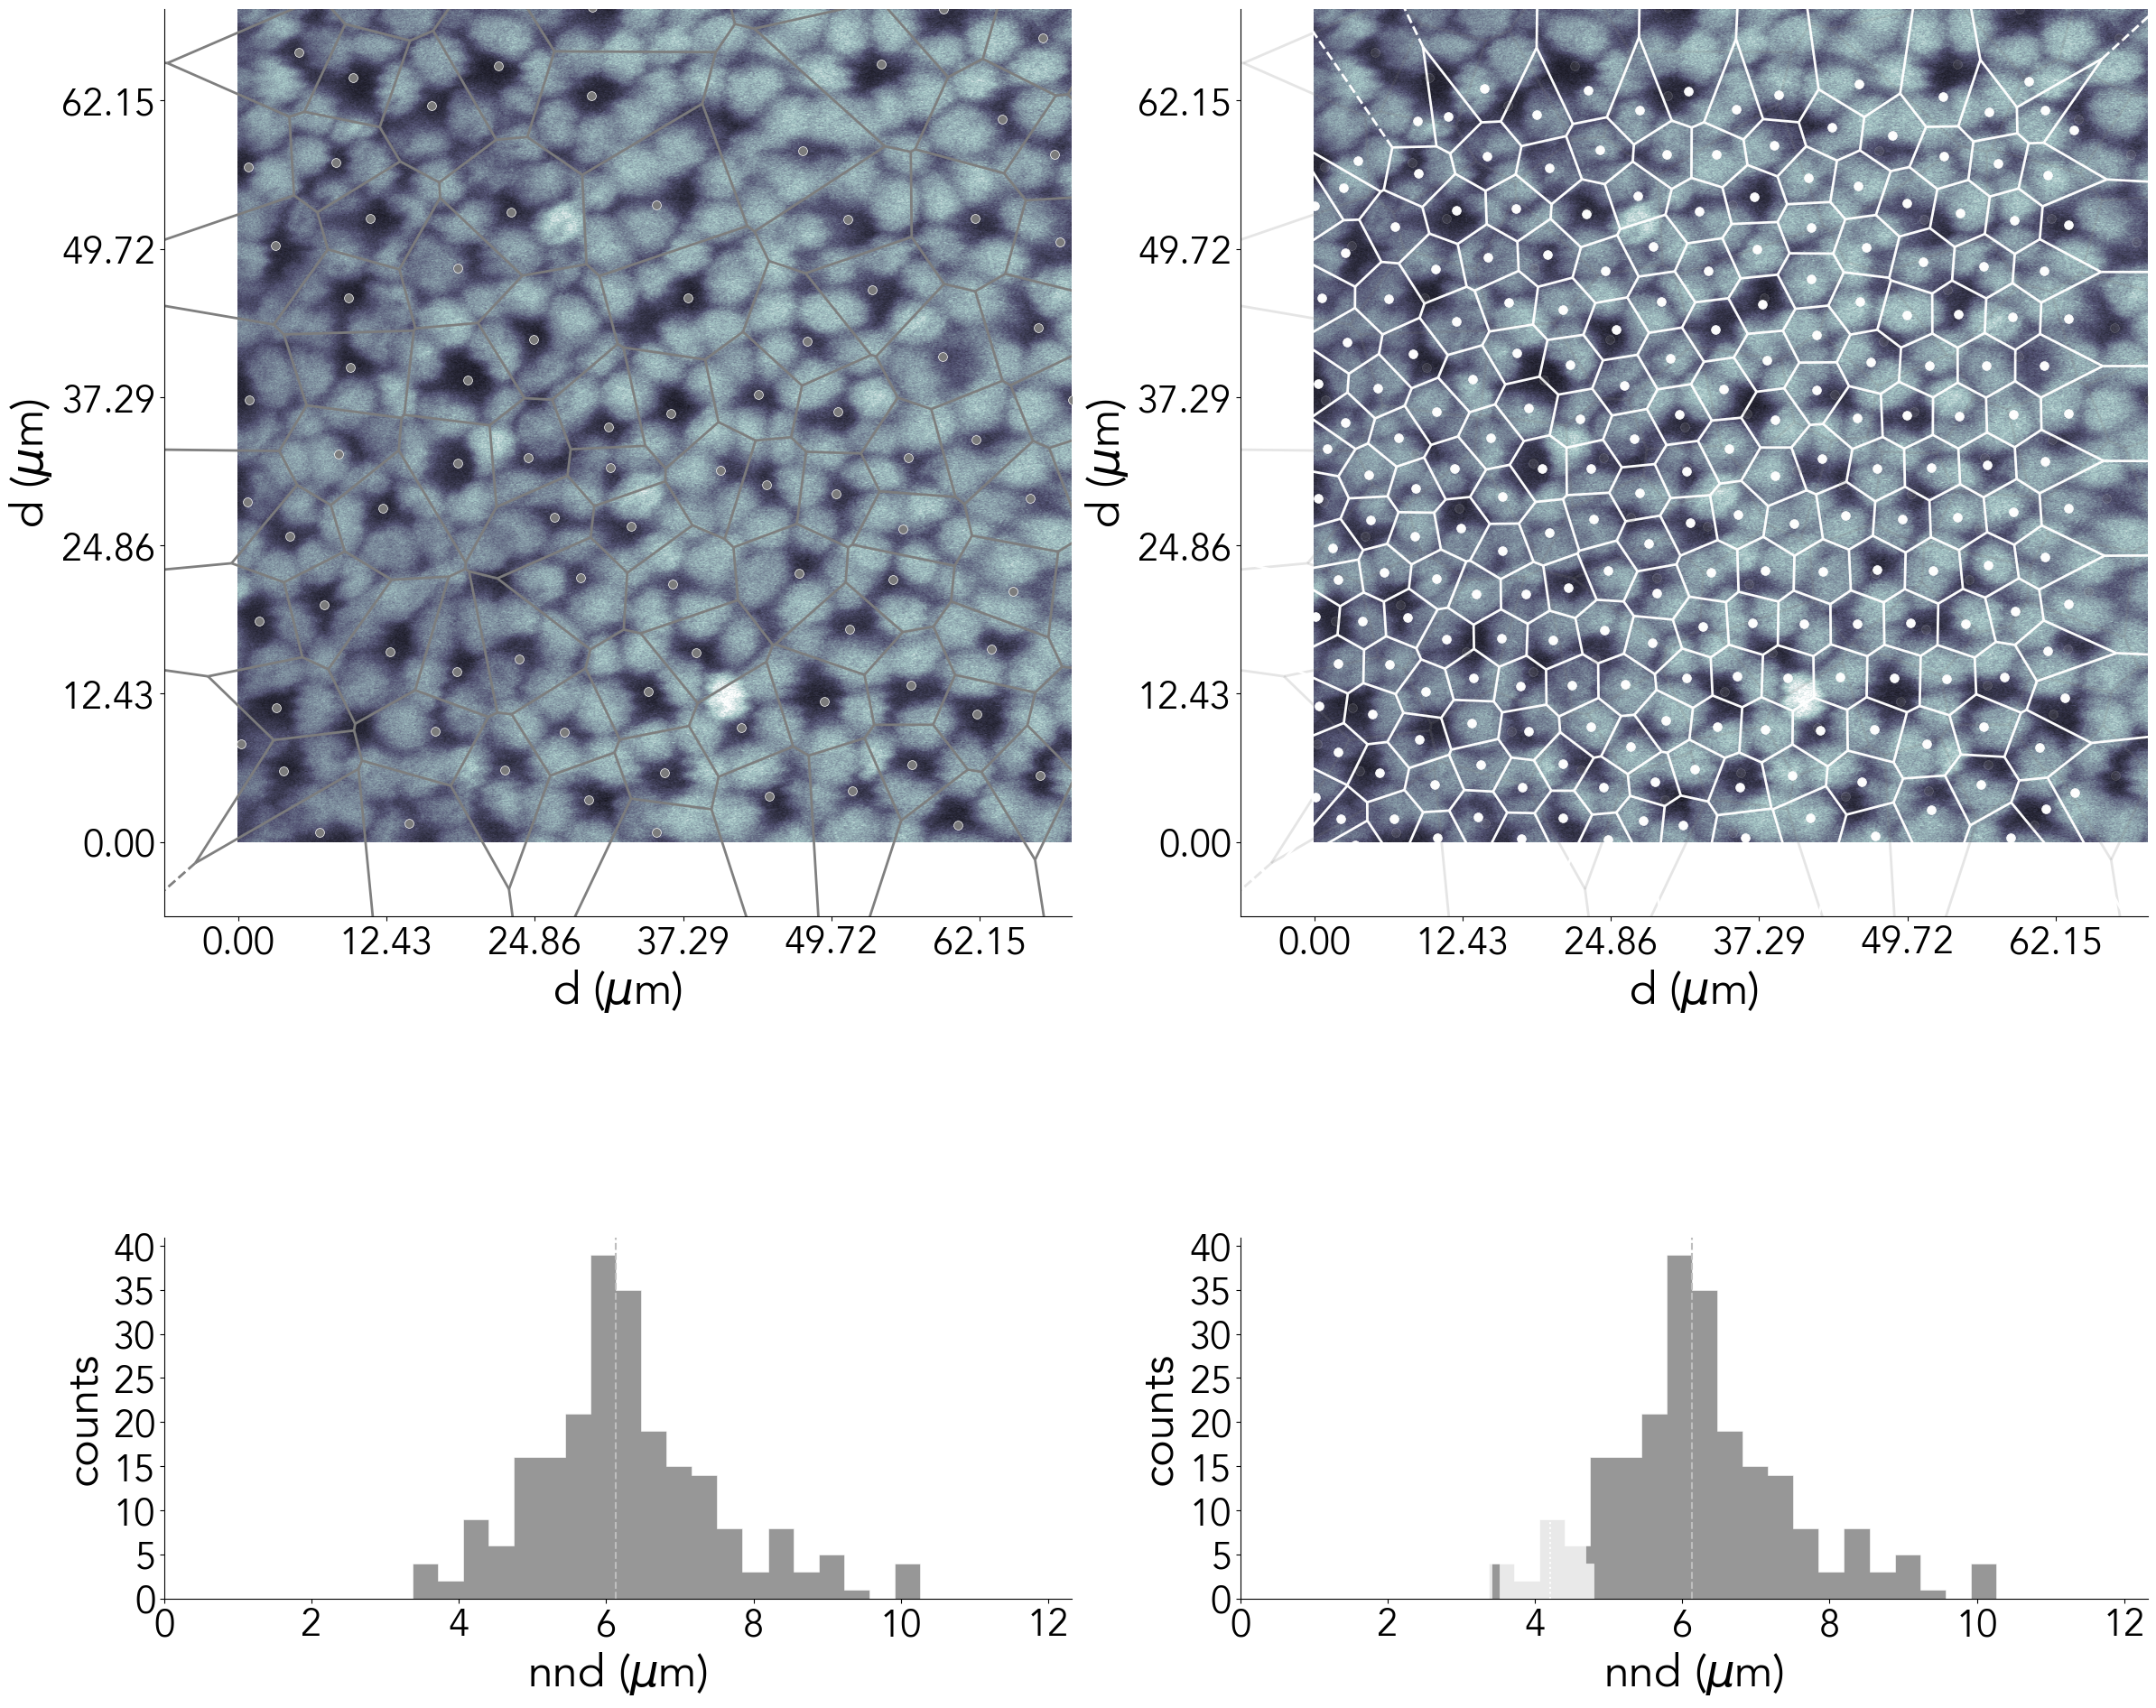

In [13]:
# # WILDTYPE (FOU) FILES
dPath = "/Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/"
fPath = [
       '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L09_002/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L09_004/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L10_002/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L10_004/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L11_002/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L11_004/',
'2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L04_002/',
'2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L04_004/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L14_002/',
'20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L14_004/',
        ]

for filepath in fPath:
    nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'R', datatype = 'labels', bg = 'R_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False) #NND for Rods
    # nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'U', datatype = 'labels', bg = 'U_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False)  #NND for UV Cones
    
# #TBX2B KO FILES

# dPath =  "Z:/Analysis/Householder/UVrod_Combined/Tbx2bKO/"
# fPath = [
#                     '20211201_5dpf_xOG_s1mCh_tbx2bF3_i02_002/',
#                     '20211201_5dpf_xOG_s1mCh_tbx2bF3_i02_002bis/',
#                     '20211201_5dpf_xOG_s1mCh_tbx2bF3_i02_004/',
#                     '20211201_5dpf_xOG_s1mCh_tbx2bF3_i11_002/',
#                     '20211201_5dpf_xOG_s1mCh_tbx2bF3_i11_004/',
#                     '20211201_5dpf_xOG_s1mCh_tbx2bF3_i12_002/',
#                     '20211201_5dpf_xOG_s1mCh_tbx2bF3_i12_004/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L09_002/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L09_004/', #r curated tiff not in folder 
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L04_002/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L26_004/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L35_002/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L35_004/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L36_002/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L36_004/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L37_002/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L13_002/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L13_004/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L19_002/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L25_002/',
#                     '20220107_5dpf_xOG_s1C_tbx2bF3_L26_002/',
#                         ]

# for filepath in fPath:
#             nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'U', datatype = 'labels', bg = 'U_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False) #NND for UV Cones
#             nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'R', datatype = 'labels', bg = 'R_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False)  #NND for rods 


    # CANNOT GET UV TO RUN DUHHHHH no uv cones in these samples 


# dPath =  "Z:/Analysis/Householder/UVrod_Combined/Tbx2aKO/"
fPath = [
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F01_002/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F01_004/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F02_002/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F03_002/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F04_002/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F05_002/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F06_002/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F07_002/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F07_004/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F08_002/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F08_004/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_M09_002/',
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_M10_002/', #U & R_mip curated tiff not in folder
#                 '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_M12_002/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L01_002/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L01_004/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L02_002/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L02_004/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L03_002/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L03_004/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L06_002/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L06_004/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L07_002/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L07_004/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L08_002/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L01_002/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L01_004/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L03_002/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L03_004/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L04_002/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L04_004/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L05_002/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L06_002/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L06_004/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L07_002/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L07_004/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L08_002/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L09_002/',
#                 '20220408_5dpf_tbx2aF3_xOG_s1C_L09_004/',
                ]

# for filepath in fPath:
    # nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'R', datatype = 'labels', bg = 'R_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False) #NND for Rods
#     # nnd = NNDcalculator(dPath = dPath + filepath, celltype = 'U', datatype = 'labels', bg = 'U_mip', nIter = 1000, saveLloyd = True, overwriteFlag = False)  #NND for UV Cones
  
    

nnd.plotAll();


In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = [
    # '20220121_5dpf_xOG_aCT_wt_L01_002/',
    # '20220121_5dpf_xOG_aCT_wt_L02_002/',
    # '20220121_5dpf_xOG_aCT_wt_L02_004/',
    # '20220121_5dpf_xOG_aCT_wt_L03_002/',
    # '20220121_5dpf_xOG_aCT_wt_L03_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_wt_L04_002/',
    # '20220121_5dpf_xOG_aCT_wt_L05_002/',
    # '20220121_5dpf_xOG_aCT_wt_L06_002/',
    # '20220121_5dpf_xOG_aCT_wt_L07_002/',
    # '20220121_5dpf_xOG_aCT_wt_L07_004/',
    # '20220121_5dpf_xOG_aCT_wt_L08_002/',
    # '20220121_5dpf_xOG_aCT_wt_L08_004/',
    # '20220121_5dpf_xOG_aCT_wt_L09_002/',
    # '20220121_5dpf_xOG_aCT_wt_L09_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_wt_L10_002/',
    # '20220121_5dpf_xOG_aCT_wt_L10_004/',
    # '20220121_5dpf_xOG_aCT_wt_L11_002/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_wt_L11_004/',
    # '20220121_5dpf_xOG_aCT_wt_L12_002/',
    # '20220121_5dpf_xOG_aCT_wt_L13_002/',
    # '20220121_5dpf_xOG_aCT_wt_L13_004/',
    # '20220121_5dpf_xOG_aCT_wt_L14_002/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_wt_L15_002/',
    # '20220121_5dpf_xOG_aCT_wt_L16_002/',
]

for filepath in fPath:
    ndd = NNDcalculator(dPath = dPath + filepath, nIter = 1000, saveLloyd = True, overwriteFlag = False)

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2f1b/'
fPath = [
    '20220121_5dpf_xOG_aCT_nr2f1b_L01_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L01_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L02_002/', # no UV cones dotted
    '20220121_5dpf_xOG_aCT_nr2f1b_L02_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L03_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L03_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L04_002/', # no UV cones dotted
    '20220121_5dpf_xOG_aCT_nr2f1b_L04_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L05_002/', # no UV cones dotted
    '20220121_5dpf_xOG_aCT_nr2f1b_L05_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L06_002/', # no UV cones dotted
    '20220121_5dpf_xOG_aCT_nr2f1b_L07_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L08_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L08_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L09_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L09_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L10_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L10_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L11_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L11_004/',
    # '20220121_5dpf_xOG_aCT_nr2f1b_L12_002/', # no UV cones dotted
]

for filepath in fPath:
    ndd = NNDcalculator(dPath = dPath + filepath, nIter = 1000, saveLloyd = True, overwriteFlag = False)

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2e3/'
fPath = [
    # '20220121_5dpf_xOG_aCT_nr2e3_L01_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L01_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L02_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L02_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L03_002/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L03_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L05_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L06_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L06_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L07_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L07_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L08_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L08_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L09_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L09_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L10_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L10_004/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L11_002/', # empty UV cones file
    # '20220121_5dpf_xOG_aCT_nr2e3_L12_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L12_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L14_002/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L15_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L15_004/', # no UV cones dotted
    # '20220121_5dpf_xOG_aCT_nr2e3_L16_002/',
    # '20220121_5dpf_xOG_aCT_nr2e3_L16_004/', # something weird happened with Voronoi
]

for filepath in fPath:
    ndd = NNDcalculator(dPath = dPath + filepath, nIter = 1000, saveLloyd = True, overwriteFlag = False)

## Plot individual retinas

In [6]:
!jupyter labextension list

JupyterLab v3.6.8
/Users/annabellarinaldi/.local/share/mamba/envs/cellCounting/share/jupyter/labextensions
        jupyterlab-jupytext v1.4.3 enabled  X (python, jupytext)
        jupyterlab_pygments v0.3.0 enabled  X (python, jupyterlab_pygments)
        ipycanvas v0.13.3 enabled OK
        jupyter-matplotlib v0.11.4 enabled OK
        ipyevents v2.0.1 enabled OK
        @jupyter-widgets/jupyterlab-manager v5.0.13 enabled OK (python, jupyterlab_widgets)


"jupyterlab-jupytext@1.4.3" is not compatible with the current JupyterLab
Conflicting Dependencies:
JupyterLab                  Extension       Package
>=3.6.8 <3.7.0              >=4.0.0 <5.0.0  @jupyterlab/application
>=3.6.8 <3.7.0              >=4.0.0 <5.0.0  @jupyterlab/apputils
>=3.6.8 <3.7.0              >=4.0.0 <5.0.0  @jupyterlab/codeeditor
>=3.6.8 <3.7.0              >=4.0.0 <5.0.0  @jupyterlab/filebrowser
>=3.6.8 <3.7.0              >=4.0.0 <5.0.0  @jupyterlab/launcher
>=3.6.8 <3.7.0              >=4.0.0 <5.0.0  @jupyterla

In [6]:
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/" #wildtype 
# dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/" #2a mutants
# dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/" #2b mutants 
fList = sorted([f for f in os.listdir(dPath) if not f.startswith('.')])

fLabel = ipywidgets.widgets.Label('Select filepath', layout=ipywidgets.Layout(width='10%', height='40px'))
fMenu = ipywidgets.Dropdown(options=fList,value=fList[0],disabled=False,layout=ipywidgets.Layout(width='30%', height='40px'))
fButton = ipywidgets.Button(description='plotNDD',disabled=False,button_style='',tooltip='plotNDD',
                            icon='check',layout=ipywidgets.Layout(width='20%', height='40px'))
fOut = ipywidgets.Output(layout=ipywidgets.Layout(width='40%', height='40px'))
def on_button_clicked(b):
    with fOut:
        fOut.clear_output()
        fPath = fMenu.value
        print(fPath)
fButton.on_click(on_button_clicked)
fSelect = ipywidgets.widgets.HBox([fLabel,fMenu,fButton,fOut])
fSelect

In [14]:
fPath = fMenu.value + '/'
ndd = NNDcalculator(dPath = dPath + fPath, celltype = 'U', datatype = 'labels', bg = 'U_mip')
ndd.plotAll();


NameError: name 'fMenu' is not defined

In [ ]:

# dAnalysis = "/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/"
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = '20220121_5dpf_xOG_aCT_wt_L01_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L02_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L02_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L03_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L04_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L05_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L06_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L07_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L07_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L08_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L08_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L09_002/'
fPath = '20220121_5dpf_xOG_aCT_wt_L10_002/'
#### fPath = '20220121_5dpf_xOG_aCT_wt_L10_004/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_wt_L11_004/'
fPath = '20220121_5dpf_xOG_aCT_wt_L12_002/'
#### fPath = '20220121_5dpf_xOG_aCT_wt_L13_002/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_wt_L13_004/'
#### fPath = '20220121_5dpf_xOG_aCT_wt_L15_002/' # incomplete dotting
#### fPath = '20220121_5dpf_xOG_aCT_wt_L16_002/' # incomplete dotting

ndd = NNDcalculator(dPath = dPath + fPath)
ndd.plotAll();


In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2e3/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L01_002/' # there's one UV cone not dotted that skews things
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L01_004/'
#### fPath = '20220121_5dpf_xOG_aCT_nr2e3_L02_002/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L02_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L03_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L05_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L06_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L06_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L07_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L08_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L08_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L09_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L09_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L10_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L10_004/' # there's one UV cone not dotted that skews things
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L12_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L15_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2e3_L16_002/'

dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2f1b/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L01_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L01_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L02_004/' # 2 UV cone missing clearly disrupt pattern
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L03_002/'
#### fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L03_004/' # incomplete dotting
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L04_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L05_004/' # 1 UV cone missing
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L07_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L08_002/' # some missing in corner
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L08_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L09_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L09_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L10_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L10_004/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L11_002/'
fPath = '20220121_5dpf_xOG_aCT_nr2f1b_L11_004/'

ndd2 = NNDcalculator(dPath = dPath + fPath)
ndd2.plotAll();


## Collect NDD distributions across cells

### F&empty;[_nr2e3_]

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = [
    '20220121_5dpf_xOG_aCT_wt_L01_002/',
    '20220121_5dpf_xOG_aCT_wt_L02_002/',
    '20220121_5dpf_xOG_aCT_wt_L02_004/',
    '20220121_5dpf_xOG_aCT_wt_L03_002/',
    '20220121_5dpf_xOG_aCT_wt_L04_002/',
    '20220121_5dpf_xOG_aCT_wt_L05_002/',
    '20220121_5dpf_xOG_aCT_wt_L06_002/',
    '20220121_5dpf_xOG_aCT_wt_L07_002/',
    '20220121_5dpf_xOG_aCT_wt_L07_004/',
    '20220121_5dpf_xOG_aCT_wt_L08_002/',
    '20220121_5dpf_xOG_aCT_wt_L08_004/',
    '20220121_5dpf_xOG_aCT_wt_L09_002/',
    '20220121_5dpf_xOG_aCT_wt_L10_002/',
    '20220121_5dpf_xOG_aCT_wt_L11_004/',
    '20220121_5dpf_xOG_aCT_wt_L12_002/',
    '20220121_5dpf_xOG_aCT_wt_L13_004/',
]
nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    # ndd = NNDcalculator(dPath = dPath + filepath)
    nnd = np.load(dPath + filepath + 'nndU.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;

    
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/nr2f1b/'
fPath = [
    '20220121_5dpf_xOG_aCT_nr2f1b_L01_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L01_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L02_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L03_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L04_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L05_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L07_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L08_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L08_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L09_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L09_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L10_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L10_004/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L11_002/',
    '20220121_5dpf_xOG_aCT_nr2f1b_L11_004/',
]
nndUMean_nr2f1b = np.empty((len(fPath),1))
nndUMean_nr2f1b[:]=np.NaN
i=0;
for filepath in fPath:
    # ndd = NNDcalculator(dPath = dPath + filepath)
    nnd = np.load(dPath + filepath + 'nndU.npy')
    nndUMean_nr2f1b[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;

In [ ]:
plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_nr2e3,nndUMean_nr2f1b],['#888888','#BF141B','#8888BB'],['o','o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2,3]);
axH.set_xticklabels(['wt','F0[nr2e3]','F0[nr2f1b]']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median UVndd  (um)', fontproperties=fontLabels)
plt.show()

## Plotting UV for *nalou* and WT 

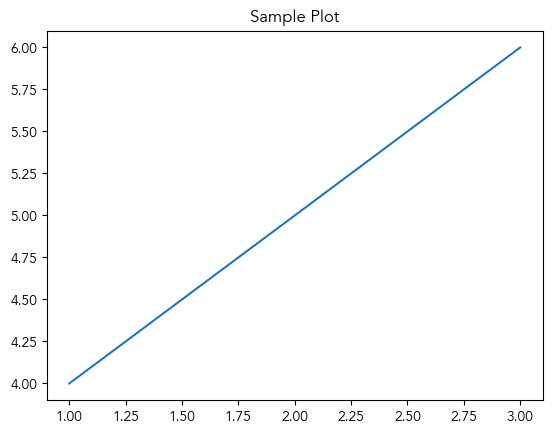

In [15]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Correct font path
font_path = '/Users/annabellarinaldi/Downloads/Anguyera Lab/Coding stuff/Avenir.ttc'

# Add the font
fm.fontManager.addfont(font_path)

# Use the font in your plots
plt.rcParams['font.family'] = 'Avenir'  # Set the font family to Avenir

# Your plotting code here
plt.plot([1, 2, 3], [4, 5, 6])
plt.title('Sample Plot')
plt.show()

In [16]:
import numpy as np

# Assuming dPath, filepath, and celltype are defined correctly
file_path = dPath + filepath + celltype + '_nnd.npy'
print("Attempting to load:", file_path)

# Check if the file exists
if os.path.exists(file_path):
    nnd = np.load(file_path)
else:
    print(f"File does not exist: {file_path}")

NameError: name 'celltype' is not defined

In [17]:
from plotParams import * 


pBGMenu = ipywidgets.Dropdown(options=['Light', 'Dark'],value='Light',disabled=False, layout=ipywidgets.Layout(width='20%', height='40px'))
pBGLabel = ipywidgets.widgets.Label('Select plotting style', layout=ipywidgets.Layout(width='20%', height='30px'))
pBG = ipywidgets.widgets.VBox([pBGLabel,pBGMenu])
pBG

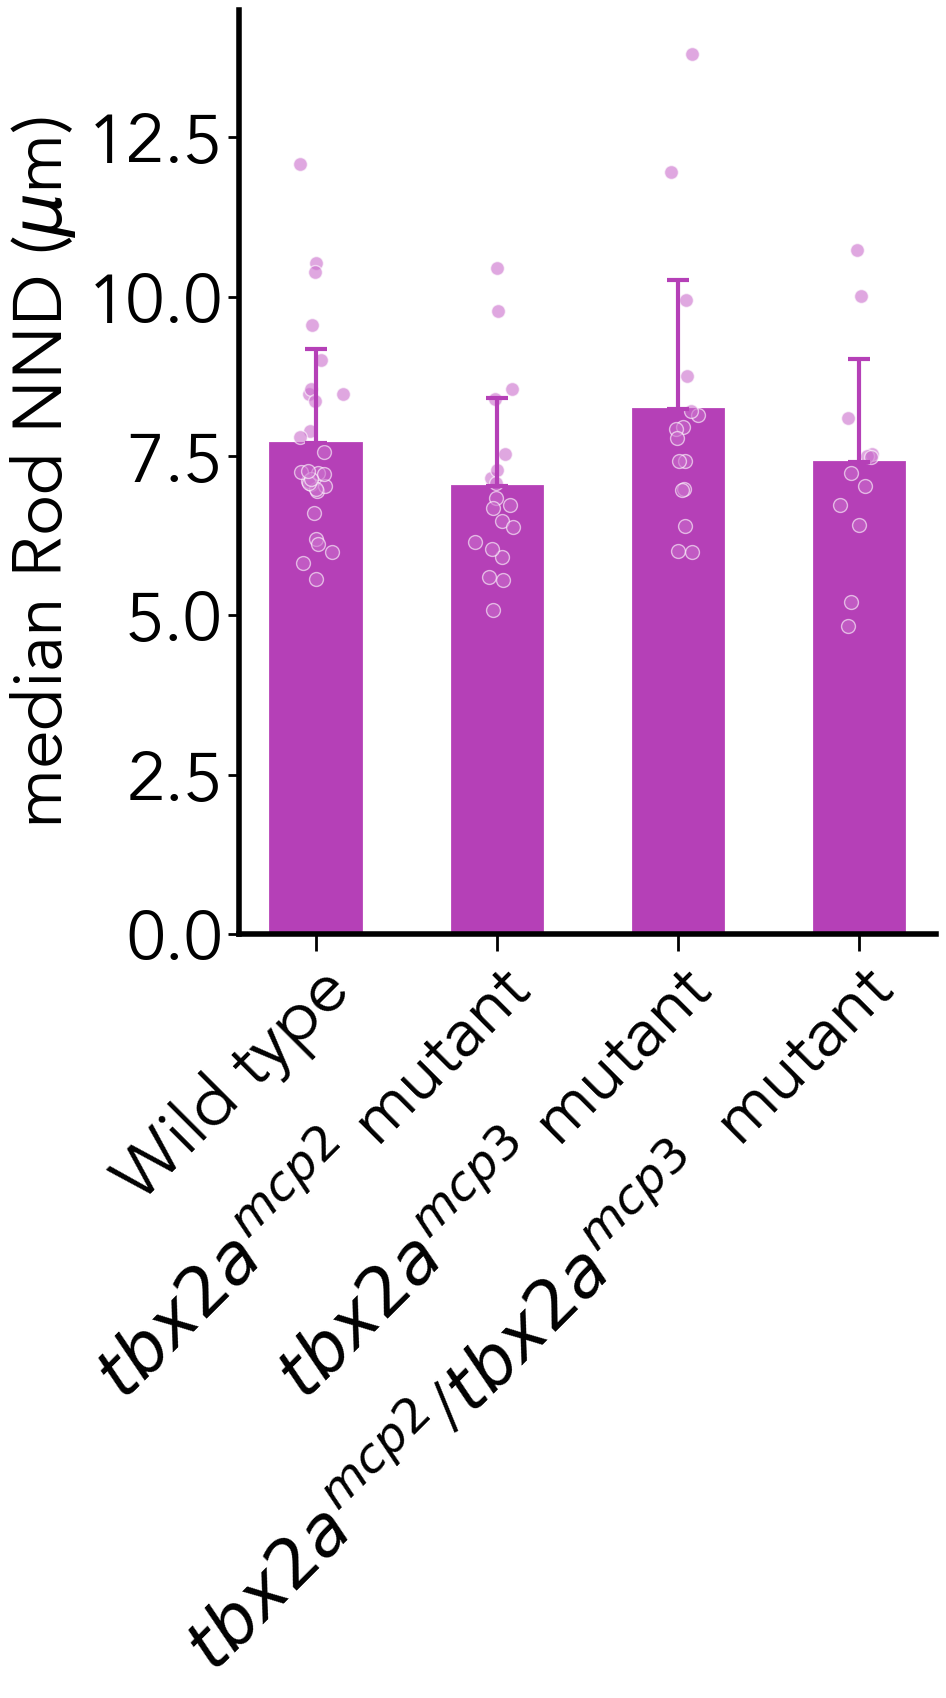

In [7]:

celltype = 'R'

#wildtype
dPath = "Z:/Analysis/Householder/Tbx2_Rescue/uninj_FOU/"
fPath = [
       '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L01_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L01_004/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L02_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L02_004/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L03_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L03_004/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L04_002/',
# '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L04_004/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L05_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L05_004/',
# '20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L01_002/',
# '20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L01_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L02_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L02_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L03_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L03_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L04_002/', #no R MIP
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L04_004/', #no R MIP/
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L05_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L05_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L06_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L06_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L07_002/', # no R MIP
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_ActualL02_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_L02_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_L04_002/', # no R mip 
'20241003_5dpf_xOPG_s1C_uninj_falou_L01_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L02_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L02_004/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L03_002/', 
'20241003_5dpf_xOPG_s1C_uninj_falou_L03_004/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L04_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L04_004/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L05_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L05_004/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L07_002/',
# # '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L01_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L01_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L02_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L03_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L03_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L04_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L04_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L05_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L05_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L06_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L06_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L07_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L07_004/',
# '2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L02_002/',
# '2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L02_004/',
# '2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L03_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L13_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L12_002/',
        ]
nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

    # TBX2B KO Retinas 
    
# # middle category USE THIS FOR THE EMPTY BAR!!!! 
# zero_stats = np.array([0.0])  # or np.zeros(n_zero_retinas) if you have multiple
    
    
    #TBX2A KO RETINAS    
dPath =  "Z:/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2aKO/"
fPath = [
                      '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L02_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L02_004/',
# '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L03_002/', # no R MIP
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L04_002/',
# '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L06_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L03_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L04_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L05_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L05_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L06_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L06_004/',
# '20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_L06_002/',
# '20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_L06_004/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L03_004/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L04_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L05_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L05_004/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L06_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L06_004/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L07_002/',
# '20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L08_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L06_002/',
'20241003_5dpf_xOPG_s1C_uninj_nalou_L01_002/', # no R MIP
'20241003_5dpf_xOPG_s1C_uninj_nalou_L01_004/', # no R MIP
'20241003_5dpf_xOPG_s1C_uninj_nalou_L02_002/',
'20241003_5dpf_xOPG_s1C_uninj_nalou_L02_004/',
'20241003_5dpf_xOPG_s1C_uninj_nalou_L04_002/', # no R MIP
# '20241206_5dpf_xOG_S1C_uninj_nalou_L01_002/',
# '20241206_5dpf_xOG_S1C_uninj_nalou_L01_004/',
# '20241206_5dpf_xOG_S1C_uninj_nalou_L06_002/',
# '20241206_5dpf_xOG_S1C_uninj_nalou_L06_004/',
                ]
nndUMean_tbx2a = np.empty((len(fPath),1))
nndUMean_tbx2a[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2a[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;

#FILEPATHFOREXON1 INX     
dPath = "Z:/Analysis/Householder/Exon1inx and Exon1xExon3/"
fPath = [
        '20260305_Tbx2aExon1F0inx_S1C_XOG_L01_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L01_004/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L02_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L02_004/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L03_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L03_004/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L04_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L07_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L08_002/',
# '20260305_Tbx2aExon1F0inx_S1C_XOG_L09_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L11_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L12_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L13_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L14_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L14_004/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L15_002/',
# '20260305_Tbx2aExon1F0inx_S1C_XOG_L16_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L16_004/',
     ]
nndUMean_exon1 = np.empty((len(fPath),1))
nndUMean_exon1[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_exon1[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;
    
    
# FILEPATH FOR EXON 1 EXON 3 INX 
dPath = "Z:/Analysis/Householder/Exon1inx and Exon1xExon3/"
fPath = [
        # '20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L01_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L02_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L02_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L03_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L03_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L04_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L04_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L06_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L06_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L07_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L07_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L08_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L08_004/',
     ] 
nndUMean_exon1exon3 = np.empty((len(fPath),1))
nndUMean_exon1exon3[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_exon1exon3[i,0] = np.median(nnd) * 79.64/2048
    i=i+1;


    
plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_tbx2a,nndUMean_exon1,nndUMean_exon1exon3],['#b540b7ff','#b540b7ff','#b540b7ff','#b540b7ff'],['o','o','o','o']): #specify order of data
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

for spine in axH.spines.values(): #use this to adjust thickness of plot spines
    spine.set_linewidth(4)    
    
    
fontLabels = formatFigureMain(fH, axH, pH)
font_path = 'C:/Users/Carin/pythonCode/Avenir.ttc'
fontTicks = font_manager.FontProperties(fname=font_path, size=30)
fontLabels = font_manager.FontProperties(fname=font_path, size=36)
fontTitle = font_manager.FontProperties(fname=font_path, size=32)

axH.set_xticks([1,2,3,4]);

axH.set_xticklabels(['Wild type',
           '$\it{tbx2a}^{mcp2}$ mutant',
           '$\it{tbx2a}^{mcp3}$ mutant',
            '$\it{tbx2a}^{mcp2}$/$\it{tbx2a}^{mcp3}$  mutant'], ha='right', rotation_mode='anchor'); #both mutants

# axH.set_xticklabels(['Wildtype', '$\it{tbx2a}$ mutant'], ha='right', rotation_mode='anchor'); #Only WT & 2A
# axH.set_xticklabels(['Wildtype','$\it{tbx2b}$ mutant','$\it{tbx2a}$ mutant','Exon1inx','Exon1xExon3']
                    
axH.tick_params(axis='x', labelsize=50)  # x tick labels size
axH.tick_params(axis='y', labelsize=50)  # y tick labels size 

axH.xaxis.set_tick_params(rotation=45, length=12) #adjust rotation and length of ticks (x axis) 
axH.tick_params(axis='both', which='major', width=2) #adjust thickness of tick marks 
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median Rod NND ($\mu$m)', fontproperties=fontLabels, fontsize=50)
axH.yaxis.set_tick_params(length=8) #adjust length of tick mark (y axis)

# plt.style.use('dark_background') #Dark background
plt.style.use('default')  # White background

plt.show()

## Save as SVG 

In [5]:

import os
outdir = r"X:/2026_TBX2Tornado/SupplementalFigure_Complementation"

fname = f"Complementation_U_NND_white_updated.svg"
fH.savefig(os.path.join(outdir, fname), bbox_inches="tight")

# fH.savefig(r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression/", bbox_inches="tight")
print("Saved as SVG into figures folder")

Saved as SVG into figures folder


## Terp AI - help with plotting 0 for Tbx2b UV cones (since there are none)

1. Make your loader robust to empty/ missing NND
    1. Replace your WT and KO loops with a helper that:
        1. loads the file if it exists
        1. if the array is empty (or file missing), returns NaN for stats
        1. and separately stores a plotting value of 0 so it shows up
2. Build two arrays: one for stats, one for plotting
3. Plot: mean/std from stats (ignoring NaNs), scatter from plot-values
    1. Replace your plotting loop with:

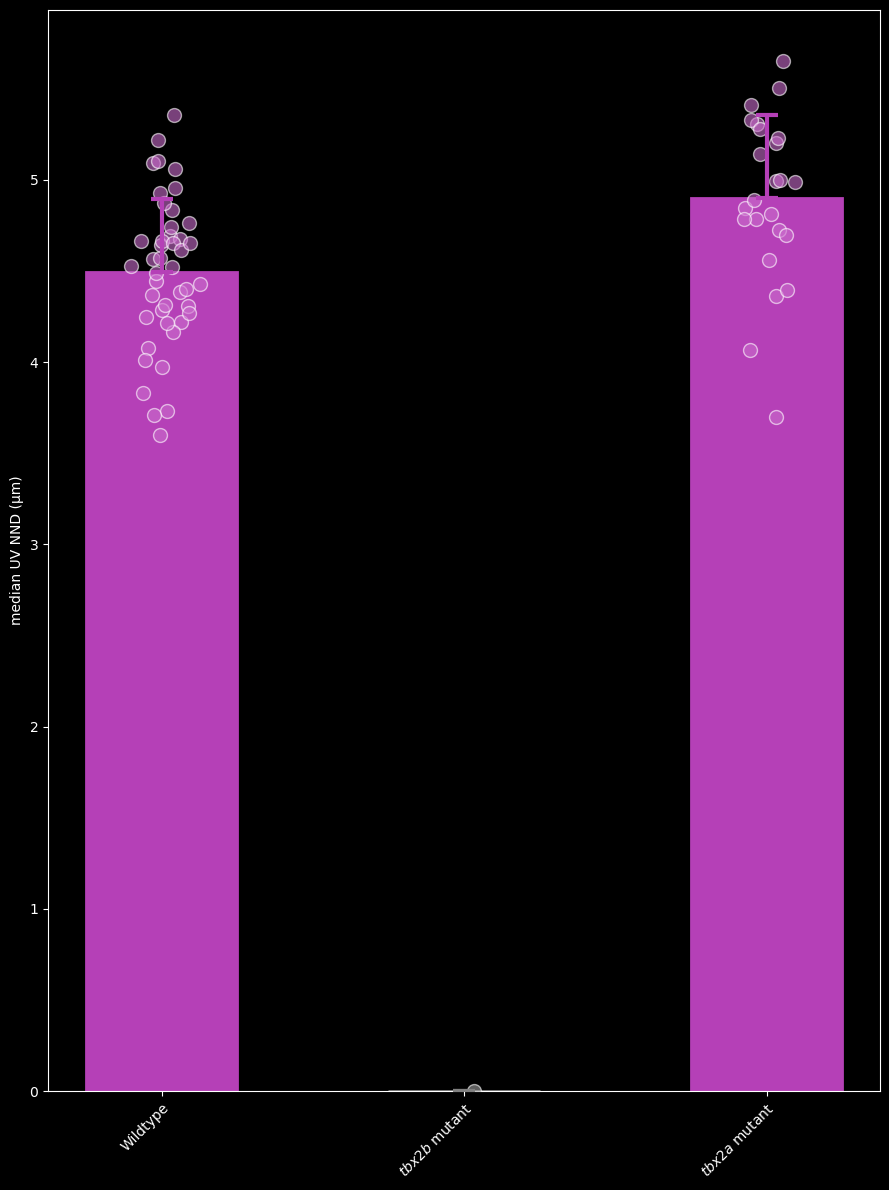

In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt

PIX2UM = 63.64/1024

def load_median_nnd_um(dPath, filepath, celltype):
    f = os.path.join(dPath, filepath, f"{celltype}_nnd.npy")
    if not os.path.exists(f):
        return np.nan
    nnd = np.load(f)
    if nnd.size == 0:
        return np.nan  # undefined if no cones / no neighbors
    return float(np.median(nnd) * PIX2UM)


# --- Use separate WT/KO paths ---
dPath_wt = "Z:/Analysis/Householder/UVrod_Combined/wt/"
fPath_wt = [
        # '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F01_002/', #files missing
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F01_004/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F02_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F03_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F03_004/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M04_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M05_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M06_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M07_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M08_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M09_002/',
        # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L04_002/', #r missing
        # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L04_004/', #r missing
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L05_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L05_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L09_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L10_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L10_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L12_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L13_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L13_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L14_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L14_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L15_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L15_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L16_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L16_004/',
        '20220408_5dpf_tbx2aF3_xOG_s1C_L02_002/',
        '20220408_5dpf_tbx2aF3_xOG_s1C_L02_004/',
        '20220408_tbx2aF3_xOG_s1C_L13_002/',
        '20220408_tbx2aF3_xOG_s1C_L13_004/',
        '20220408_tbx2aF3_xOG_s1C_L14_002/',
        '20220408_tbx2aF3_xOG_s1C_L14_004/',
        '20220408_tbx2aF3_xOG_s1C_L15_002/',
        '20220408_tbx2aF3_xOG_s1C_L15_004/',
        '20220408_tbx2aF3_xOG_s1C_L16_002/',
        '20220408_tbx2aF3_xOG_s1C_L16_004/',
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i01_002/', #issue with UV
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i03_002/', #issue with UV
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i03_004/', #issue with UV
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i04_002/', #issue with UV
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i04_004/', #issue with UV
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i05_002/', #issue with UV
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i05_004/',#issue with UV
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i06_002/', #issue with UV
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i06_004/', #issue with UV
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i07_002/', #issue with UV
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i09_002/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i09_004/',
        # '20211201_5dpf_xOG_s1mCh_tbx2bF3_i10_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L01_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L02_002/', #u & r nnd missing
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L03_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L05_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L06_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L06_004/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L08_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L10_002/', #issue with UV
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L11_002/', #issue with UV
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L12_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L27_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L28_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L29_002/', #issue with UV
        '20220107_5dpf_xOG_s1C_tbx2bF3_L30_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L31_002/', #issue with UV
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L32_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L33_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L34_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L39_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L40_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L14_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L15_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L16_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L17_002/', # no curated seg saved
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L18_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L20_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L21_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L22_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L23_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L24_002/', #u & R nnd not saved
        ]   # WT list

dPath_ko = "Z:/Analysis/Householder/UVrod_Combined/Tbx2aKO/"
fPath_ko = [
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F01_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F01_004/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F02_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F03_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F04_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F05_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F06_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F07_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F07_004/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F08_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F08_004/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_M09_002/',
                # '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_M10_002/', #U & R_mip curated tiff not in folder
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_M12_002/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L01_002/', #r nnd did not save 
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L01_004/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L02_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L02_004/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L03_002/',#r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L03_004/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L06_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L06_004/', #r nnd did not save
                '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L07_002/',
                '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L07_004/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L08_002/', #r nnd did not save
                '20220408_5dpf_tbx2aF3_xOG_s1C_L01_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L01_004/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L03_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L03_004/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L04_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L04_004/',
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L05_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L06_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L06_004/', #r nnd did not save
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L07_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L07_004/', #r nnd did not save
                '20220408_5dpf_tbx2aF3_xOG_s1C_L08_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L09_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L09_004/',
                ]   # KO list

celltype = "U"

# --- compute WT and KO as before ---
wt_stats = np.array([load_median_nnd_um(dPath_wt, fp, celltype) for fp in fPath_wt])
ko_stats = np.array([load_median_nnd_um(dPath_ko, fp, celltype) for fp in fPath_ko])

# middle category USE THIS FOR THE EMPTY BAR!!!! 
zero_stats = np.array([0.0])  # or np.zeros(n_zero_retinas) if you have multiple

# --- REORDER HERE: WT, ZERO, KO ---
groups_stats = [wt_stats, zero_stats, ko_stats]
labels       = ['Wildtype', '$\it{tbx2b}$ mutant', r'$\it{tbx2a}$ mutant']
colors       = ['#b540b7ff', '#808080ff', '#b540b7ff']
markers      = ['o', 'o', 'o']

fH, axH = plt.subplots(figsize=[9,12])
x = np.arange(1, 4)

for xi, vals, c, m in zip(x, groups_stats, colors, markers):
    if np.all(np.isnan(vals)):
        mean_i, std_i = 0.0, 0.0
        vals_plot = np.array([0.0])
    else:
        mean_i = np.nanmean(vals)
        std_i  = np.nanstd(vals)
        vals_plot = vals[~np.isnan(vals)]

    axH.bar(xi, mean_i, width=0.5, color=c, linewidth=2, edgecolor=c)
    axH.errorbar(xi, mean_i, yerr=[[0],[std_i]], ecolor=c, elinewidth=3,
                 capsize=8, capthick=3, zorder=9)

    jitter = np.random.randn(len(vals_plot)) * 0.05
    axH.scatter(np.ones(len(vals_plot))*xi + jitter, vals_plot,
                color=lighten_color(c,.75), zorder=8, marker=m,
                s=100, edgecolor=baseColor, linewidth=1, alpha=0.6)

axH.set_xticks(x)
axH.set_xticklabels(labels, ha='right', rotation=45, rotation_mode='anchor')
axH.set_ylabel('median UV NND (µm)')
plt.tight_layout()

## Save as SVG to folder in NAS/Google Drive

In [11]:

import os
outdir = '/Users/annabellarinaldi/Downloads/Anguyera Lab/Plots'
# outdir = r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression"
# outdir = r"W:/2026_TBX2Tornado/Fig1_UVrod"

fname = f"TBX2KO_UV_NND_light_WT.svg"
fH.savefig(os.path.join(outdir, fname), bbox_inches="tight")

# fH.savefig(r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression/", bbox_inches="tight")
print("Saved as SVG into figures folder")

Saved as SVG into figures folder


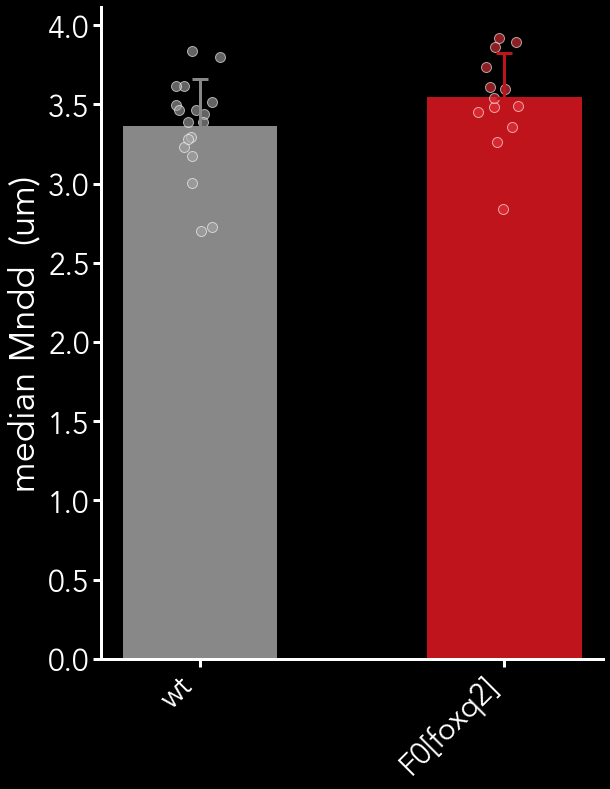

In [30]:





celltype = 'M'

dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRfoxq2F0/mw2Gt2T/wt/'
fPath = [
'20210716_5dpf_m2G_t2T_uninj_L101b/',
'20210716_5dpf_m2G_t2T_uninj_L101d/',
'20210716_5dpf_m2G_t2T_uninj_L102b/',
'20210716_5dpf_m2G_t2T_uninj_L103b/',
'20210716_5dpf_m2G_t2T_uninj_L103d/',
'20210716_5dpf_m2G_t2T_uninj_L104b/',
'20210716_5dpf_m2G_t2T_uninj_L104d/',
'20210716_5dpf_m2G_t2T_uninj_L105b/',
'20210716_5dpf_m2G_t2T_uninj_L106b/',
'20210716_5dpf_m2G_t2T_uninj_L106d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L01b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L03b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L03d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L05b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L05d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L12b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L12d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_uninj_L14b/',
]


nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;

dPath = 'D:/Analysis/F0Tbx2arescueHalo_20241003/s1CxOG/inj2arescue/'
fPath = [
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L01b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L01d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L02b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L02d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L03b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L03d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L04b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L05b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L05d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L06b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L06d/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L07b/',
'20210716_5dpf_t2T_m2G_mZpr1405_rbSopCy5_CRfoxq2_L07d/',
]


nndUMean_foxq2 = np.empty((len(fPath),1))
nndUMean_foxq2[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_foxq2[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;
    
plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_foxq2],['#888888','#BF141B'],['o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2]);
axH.set_xticklabels(['wt','F0[foxq2]']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median {0}ndd  (um)'.format(celltype), fontproperties=fontLabels)
plt.show()

## Plotting Rod NND (WT, 2b KO, 2a KO)

In [94]:

celltype = 'R'

#wildtype
dPath = "Z:/Analysis/Householder/UVrod_Combined/wt/"
fPath = [
        # '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F01_002/', #files missing
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F01_004/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F02_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F03_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F03_004/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M04_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M05_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M06_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M07_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M08_002/',
        '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_M09_002/',
        # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L04_002/', #r missing
        # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L04_004/', #r missing
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L05_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L05_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L09_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L10_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L10_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L12_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L13_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L13_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L14_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L14_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L15_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L15_004/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L16_002/',
        '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L16_004/',
        '20220408_5dpf_tbx2aF3_xOG_s1C_L02_002/',
        '20220408_5dpf_tbx2aF3_xOG_s1C_L02_004/',
        '20220408_tbx2aF3_xOG_s1C_L13_002/',
        '20220408_tbx2aF3_xOG_s1C_L13_004/',
        '20220408_tbx2aF3_xOG_s1C_L14_002/',
        '20220408_tbx2aF3_xOG_s1C_L14_004/',
        '20220408_tbx2aF3_xOG_s1C_L15_002/',
        '20220408_tbx2aF3_xOG_s1C_L15_004/',
        '20220408_tbx2aF3_xOG_s1C_L16_002/',
        '20220408_tbx2aF3_xOG_s1C_L16_004/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i01_002/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i03_002/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i03_004/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i04_002/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i04_004/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i05_002/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i05_004/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i06_002/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i06_004/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i07_002/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i09_002/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i09_004/',
        '20211201_5dpf_xOG_s1mCh_tbx2bF3_i10_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L01_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L02_002/', #u & r nnd missing
        '20220107_5dpf_xOG_s1C_tbx2bF3_L03_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L05_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L06_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L06_004/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L08_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L10_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L11_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L12_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L27_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L28_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L29_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L30_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L31_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L32_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L33_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L34_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L39_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L40_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L14_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L15_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L16_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L17_002/', # no curated seg saved
        '20220107_5dpf_xOG_s1C_tbx2bF3_L18_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L20_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L21_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L22_002/',
        '20220107_5dpf_xOG_s1C_tbx2bF3_L23_002/',
        # '20220107_5dpf_xOG_s1C_tbx2bF3_L24_002/', #u & R nnd not saved
        ]


nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;

#  #TBX2B KO FILES
dPath =  "Z:/Analysis/Householder/UVrod_Combined/Tbx2bKO/"
fPath = [
                    '20211201_5dpf_xOG_s1mCh_tbx2bF3_i02_002/',
                    '20211201_5dpf_xOG_s1mCh_tbx2bF3_i02_002bis/',
                    '20211201_5dpf_xOG_s1mCh_tbx2bF3_i02_004/',
                    '20211201_5dpf_xOG_s1mCh_tbx2bF3_i11_002/',
                    '20211201_5dpf_xOG_s1mCh_tbx2bF3_i11_004/',
                    '20211201_5dpf_xOG_s1mCh_tbx2bF3_i12_002/',
                    '20211201_5dpf_xOG_s1mCh_tbx2bF3_i12_004/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L09_002/',
                    # '20220107_5dpf_xOG_s1C_tbx2bF3_L09_004/', #r curated tiff not in folder 
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L04_002/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L26_004/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L35_002/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L35_004/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L36_002/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L36_004/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L37_002/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L13_002/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L13_004/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L19_002/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L25_002/',
                    '20220107_5dpf_xOG_s1C_tbx2bF3_L26_002/',
                        ]


nndUMean_tbx2b = np.empty((len(fPath),1))
nndUMean_tbx2b[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2b[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;

#Tbx2a KO Samples     
dPath =  "Z:/Analysis/Householder/UVrod_Combined/Tbx2aKO/"
fPath = [
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F01_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F01_004/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F02_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F03_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F04_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F05_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F06_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F07_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F07_004/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F08_002/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_F08_004/',
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_M09_002/',
                # '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_M10_002/', #U & R_mip curated tiff not in folder
                '20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_nalou_M12_002/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L01_002/', #r nnd did not save 
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L01_004/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L02_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L02_004/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L03_002/',#r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L03_004/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L06_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L06_004/', #r nnd did not save
                '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L07_002/',
                '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L07_004/',
                # '20220408_5dpf_tbx2aF1xF3_xOG_s1C_L08_002/', #r nnd did not save
                '20220408_5dpf_tbx2aF3_xOG_s1C_L01_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L01_004/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L03_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L03_004/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L04_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L04_004/',
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L05_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L06_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L06_004/', #r nnd did not save
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L07_002/', #r nnd did not save
                # '20220408_5dpf_tbx2aF3_xOG_s1C_L07_004/', #r nnd did not save
                '20220408_5dpf_tbx2aF3_xOG_s1C_L08_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L09_002/',
                '20220408_5dpf_tbx2aF3_xOG_s1C_L09_004/',
                ]


nndUMean_tbx2a = np.empty((len(fPath),1))
nndUMean_tbx2a[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2a[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;



plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_tbx2b,nndUMean_tbx2a],['#888888','#888888','#888888'],['o','o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

for spine in axH.spines.values(): #use this to adjust thickness of plot spines
    spine.set_linewidth(4)    
    
    
fontLabels = formatFigureMain(fH, axH, pH)
font_path = 'C:/Users/Carin/pythonCode/Avenir.ttc'
fontTicks = font_manager.FontProperties(fname=font_path, size=30)
fontLabels = font_manager.FontProperties(fname=font_path, size=36)
fontTitle = font_manager.FontProperties(fname=font_path, size=32)

axH.set_xticks([1,2,3]);
axH.set_xticklabels(['Wildtype','$\it{tbx2b}$ mutant','$\it{tbx2a}$ mutant'], ha='right', rotation_mode='anchor');
axH.tick_params(axis='both', which='major', width=2) #adjust thickness of tick marks 
axH.xaxis.set_tick_params(rotation=45)


axH.tick_params(axis='x', labelsize=50)  # x tick labels size
axH.tick_params(axis='y', labelsize=50)  # y tick labels size 

# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median {0}ndd  ($\mu$m)'.format(celltype), fontproperties=fontLabels, fontsize=50)
axH.yaxis.set_tick_params(length=8) #adjust length of tick mark (y axis)

# plt.style.use('dark_background') #Dark background
plt.style.use('default')  # White background

plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'Z:/Analysis/Householder/UVrod_Combined/wt/20221118_5dpf_xOG_s1C_PNA647_tbx2aF4_wt_F01_004/R_nnd.npy'

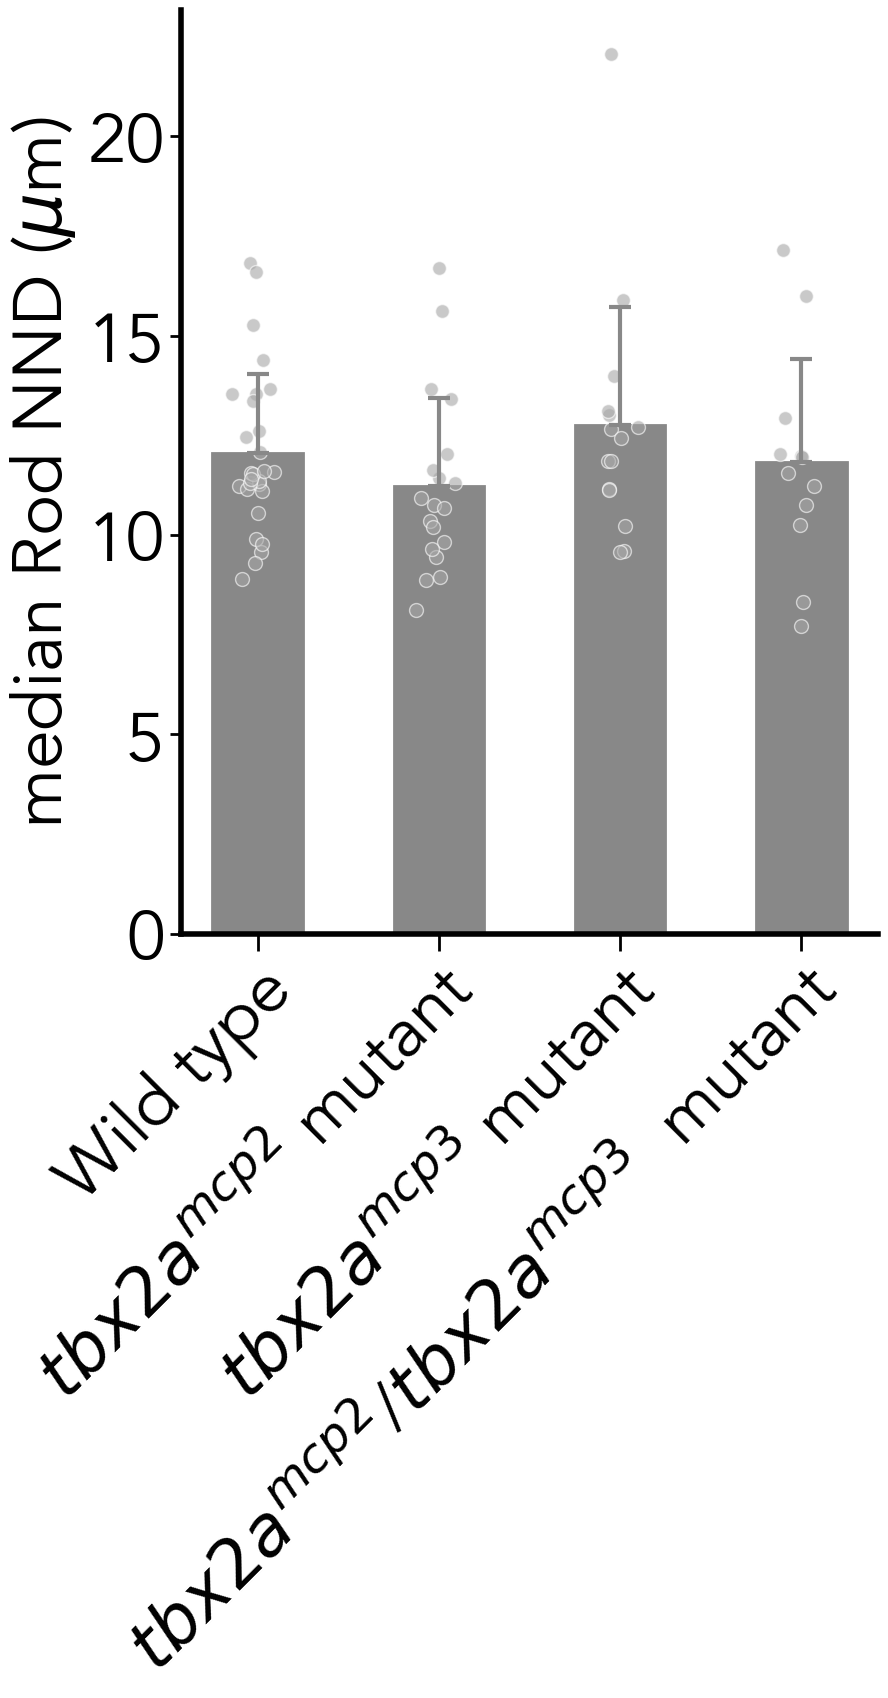

In [9]:
celltype = 'R'

#wildtype
dPath = "Z:/Analysis/Householder/Tbx2_Rescue/uninj_FOU/"
fPath = [
       # '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L01_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L01_004/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L02_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L02_004/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L03_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L03_004/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L04_002/',
# '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L04_004/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L05_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L05_004/',
# '20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L01_002/',
# '20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L01_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L02_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L02_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L03_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L03_004/',
# '20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L04_002/',
# '20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L04_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L05_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L05_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L06_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L06_004/',
# '20250123_2ahetinx_S1C_xOG_F02b2aSWAP_FOU_uninj_L07_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_ActualL02_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_L02_002/',
# '20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_L04_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L01_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L02_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L02_004/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L03_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L03_004/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L04_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L04_004/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L05_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L05_004/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L07_002/',
# # '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L01_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L01_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L02_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L03_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L03_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L04_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L04_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L05_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L05_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L06_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L06_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L07_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_fou_s1C_xOG_L07_004/',
# '2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L02_002/',
# '2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L02_004/',
# '2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L03_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L13_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L12_002/',
        ]
nndRMean_wt = np.empty((len(fPath),1))
nndRMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndRMean_wt[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;

    # TBX2B KO Retinas 
    
# #  #TBX2B KO FILES
# dPath =  "/Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2bKO/"
# fPath = [
#                    # '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L09_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L09_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L10_002/',
# # '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L10_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L11_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L11_004/',
# '2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L04_002/',
# '2025071_5dpf_2bhetinx_s1C_xOG_uninj_lor_L04_004/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L14_002/',
# '20250711_5dpf_tbx2bhetinx_uninj_lor_s1C_xOG_L14_004/',
#                         ]


# nndRMean_tbx2b = np.empty((len(fPath),1))
# nndRMean_tbx2b[:]=np.NaN
# i=0;
# for filepath in fPath:
#     nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
#     nndRMean_tbx2b[i,0] = np.median(nnd) * 63.64/1024
#     i=i+1;
    
    
    #TBX2A KO RETINAS    
dPath =   "Z:/Analysis/Householder/Tbx2_Rescue/uninj_Tbx2aKO/"
fPath = [
                      '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L02_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L02_004/',
# '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L03_002/',
'20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L04_002/',
# '20241024_tbx2ahetmutinx_5dpf_s1c_xOG_NALOU_Uninj_L06_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L03_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L04_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L05_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L05_004/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L06_002/',
'20250123_2ahetinx_S1C_xOG_F02b2aSWAP_nalou_uninj_L06_004/',
# '20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_L06_002/',
# '20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_WT_L06_004/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L03_004/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L04_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L05_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L05_004/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L06_002/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L06_004/',
'20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L07_002/',
# '20240906_Tbx2aHETinx_5dpf_s1c_xOG_Uninj_nalou_L08_002/',
'20241003_5dpf_xOPG_s1C_uninj_falou_L06_002/',
# '20241003_5dpf_xOPG_s1C_uninj_nalou_L01_002/',
# '20241003_5dpf_xOPG_s1C_uninj_nalou_L01_004/',
'20241003_5dpf_xOPG_s1C_uninj_nalou_L02_002/',
'20241003_5dpf_xOPG_s1C_uninj_nalou_L02_004/',
# '20241003_5dpf_xOPG_s1C_uninj_nalou_L04_002/',
# '20241206_5dpf_xOG_S1C_uninj_nalou_L01_002/',
# '20241206_5dpf_xOG_S1C_uninj_nalou_L01_004/',
# '20241206_5dpf_xOG_S1C_uninj_nalou_L06_002/',
# '20241206_5dpf_xOG_S1C_uninj_nalou_L06_004/',
                ]
nndRMean_tbx2a = np.empty((len(fPath),1))
nndRMean_tbx2a[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndRMean_tbx2a[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;
dPath = "Z:/Analysis/Householder/Exon1inx and Exon1xExon3/"
fPath = [
        '20260305_Tbx2aExon1F0inx_S1C_XOG_L01_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L01_004/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L02_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L02_004/',
# '20260305_Tbx2aExon1F0inx_S1C_XOG_L03_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L03_004/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L04_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L07_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L08_002/',
# '20260305_Tbx2aExon1F0inx_S1C_XOG_L09_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L11_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L12_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L13_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L14_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L14_004/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L15_002/',
# '20260305_Tbx2aExon1F0inx_S1C_XOG_L16_002/',
'20260305_Tbx2aExon1F0inx_S1C_XOG_L16_004/',
     ]
nndRMean_exon1 = np.empty((len(fPath),1))
nndRMean_exon1[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndRMean_exon1[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;
dPath ="Z:/Analysis/Householder/Exon1inx and Exon1xExon3/"
fPath = [
        # '20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L01_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L02_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L02_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L03_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L03_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L04_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L04_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L06_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L06_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L07_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L07_004/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L08_002/',
'20260409_Tbx2a_5d_exon1f1xexon3mut_S1C_XOG_L08_004/',
     ] 
nndRMean_exon1exon3 = np.empty((len(fPath),1))
nndRMean_exon1exon3[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndRMean_exon1exon3[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;


    
plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndRMean_wt,nndRMean_tbx2a,nndRMean_exon1,nndRMean_exon1exon3],['#888888','#888888','#888888','#888888'],['o','o','o','o']): #specify order of data
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

for spine in axH.spines.values(): #use this to adjust thickness of plot spines
    spine.set_linewidth(4)    
    
    
fontLabels = formatFigureMain(fH, axH, pH)
font_path = 'C:/Users/Carin/pythonCode/Avenir.ttc'
fontTicks = font_manager.FontProperties(fname=font_path, size=30)
fontLabels = font_manager.FontProperties(fname=font_path, size=36)
fontTitle = font_manager.FontProperties(fname=font_path, size=32)

axH.set_xticks([1,2,3,4]);

axH.set_xticklabels(['Wild type',
           '$\it{tbx2a}^{mcp2}$ mutant',
           '$\it{tbx2a}^{mcp3}$ mutant',
            '$\it{tbx2a}^{mcp2}$/$\it{tbx2a}^{mcp3}$  mutant'], ha='right', rotation_mode='anchor'); #both mutants

# axH.set_xticklabels(['Wildtype', '$\it{tbx2a}$ mutant'], ha='right', rotation_mode='anchor'); #Only WT & 2A
# axH.set_xticklabels(['Wildtype','$\it{tbx2b}$ mutant','$\it{tbx2a}$ mutant','Exon1inx','Exon1xExon3']
                    
axH.tick_params(axis='x', labelsize=50)  # x tick labels size
axH.tick_params(axis='y', labelsize=50)  # y tick labels size 

axH.xaxis.set_tick_params(rotation=45, length=12) #adjust rotation and length of ticks (x axis) 
axH.tick_params(axis='both', which='major', width=2) #adjust thickness of tick marks 
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median Rod NND ($\mu$m)', fontproperties=fontLabels, fontsize=50)
axH.yaxis.set_tick_params(length=8) #adjust length of tick mark (y axis)

# plt.style.use('dark_background') #Dark background
plt.style.use('default')  # White background

plt.show()

### SAVE AS SVG 

In [10]:
import os
outdir = 'X:/2026_TBX2Tornado/SupplementalFigure_Complementation'
# outdir = r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression"
# outdir = r"W:/2026_TBX2Tornado/Fig1_UVrod"

fname = f"Complementation_R_NND_light_WT.svg"
fH.savefig(os.path.join(outdir, fname), bbox_inches="tight")

# fH.savefig(r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression/", bbox_inches="tight")
print("Saved as SVG into figures folder")

Saved as SVG into figures folder


In [ ]:
/Volumes/Imaging/Analysis/Householder/Tbx2_Rescue/uninj_FOU/20241024_tbx2ahetmutinx_5dpf_s1c_xOG_FOU_Uninj_L01_002/R_nnd.npy

In [21]:
#import numpy as np
from scipy.stats import kruskal
import scikit_posthocs

# Example: you computed these earlier for celltype = 'L'
# nndUMean_wt, nndUMean_tbx2a (Tbx2bKO), nndUMean_tbx2b (Tbx2aKO)

nnd_by_pr = {
    'R': {
        'wt': np.ravel(nndRMean_wt),
        'tbx2a_exon3': np.ravel(nndRMean_tbx2a),
        'tbx2a_exon1': np.ravel(nndRMean_exon1),
        'tbx2a_exon1x3': np.ravel(nndRMean_exon1exon3)
    }
}

geneList = ['nndRMean_wt', 'nndRMean_tbx2a', 'nndRMean_exon1', 'nndRMean_exon1exon3']

photoreceptors = ['R']  # Keep only those you actually have in nnd_by_pr

for pr in photoreceptors:
    wtCount = nnd_by_pr[pr]['wt']
    tbx2aexon3Count = nnd_by_pr[pr]['tbx2a_exon3']
    tbx2aexon1Count = nnd_by_pr[pr]['tbx2a_exon1']
    tbx2aexon1x3Count = nnd_by_pr[pr]['tbx2a_exon1x3']

    # Drop NaNs
    wtCount = wtCount[~np.isnan(wtCount)]
    tbx2aexon3Count = tbx2aexon3Count[~np.isnan(tbx2aexon3Count)]
    tbx2aexon1Count = tbx2aexon1Count[~np.isnan(tbx2aexon1Count)]
    tbx2aexon1x3Count = tbx2aexon1x3Count[~np.isnan(tbx2aexon1x3Count)]

    # Perform Kruskal-Wallis test
    h, p = kruskal(wtCount, tbx2aexon3Count, tbx2aexon1Count, tbx2aexon1x3Count)

    print(f'\nFor {pr} NND medians:')
    print('\t\tH = {0:.3f}, p = {1:.20f}, nEyes: wt = {2:.0f}; {3} = {4:.0f}; {5} = {6:.0f}'.format(
        h, p, len(wtCount), geneList[1], len(tbx2aexon3Count), geneList[2], len(tbx2aexon1Count)
    ))

    posthoc_names = ['wt', 'tbx2a_exon3', 'tbx2a_exon1', 'tbx2a_exon1x3']
    r = scikit_posthocs.posthoc_conover(
        [wtCount, tbx2aexon3Count, tbx2aexon1Count, tbx2aexon1x3Count],
        p_adjust='Bonferroni'
    )

    print('\tConover-Iman posthoc + Bonferroni p adjustment:')
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format(posthoc_names[0], posthoc_names[1], r.iloc[0, 1]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format(posthoc_names[0], posthoc_names[2], r.iloc[0, 2]))
    print('\t\t{0} vs. {1}: p = {2:.20f} | p = {2}'.format(posthoc_names[0], posthoc_names[3], r.iloc[0, 2]))
 


For R NND medians:
		H = 3.943, p = 0.26771370822910423026, nEyes: wt = 28; nndRMean_tbx2a = 19; nndRMean_exon1 = 15
	Conover-Iman posthoc + Bonferroni p adjustment:
		wt vs. tbx2a_exon3: p = 0.77999355852036467152 | p = 0.7799935585203647
		wt vs. tbx2a_exon1: p = 1.00000000000000000000 | p = 1.0
		wt vs. tbx2a_exon1x3: p = 1.00000000000000000000 | p = 1.0


#### PLotting INFO: 
   ```
   def formatFigureMain(figH, axH, plotH):
    font_path = 'C:/Users/Carin/pythonCode/Avenir.ttc'
    fontTicks = font_manager.FontProperties(fname=font_path, size=30)
    fontLabels = font_manager.FontProperties(fname=font_path, size=36)
    fontTitle = font_manager.FontProperties(fname=font_path, size=32)
    axH.set_xscale('linear')
    axH.spines['top'].set_visible(False)
    axH.spines['right'].set_visible(False)
    ```

## Save ROD NND as SVG to NAS/Google Drive 
>PLS update your Filename GORLLLL

In [13]:

import os
# outdir = r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression"
outdir = r"/Users/annabellarinaldi/Downloads/Anguyera Lab/Plots"
# outdir = r"W:/2026_TBX2Tornado/Fig1_UVrod"
fname = f"TBX2KO_Rod_NND_light_WT.svg"
fH.savefig(os.path.join(outdir, fname), bbox_inches="tight")

# fH.savefig(r"G:/Shared drives/labNotebook/Householder/Figures/TBX2Misexpression/", bbox_inches="tight")
print("Saved as SVG into figures folder")

Saved as SVG into figures folder


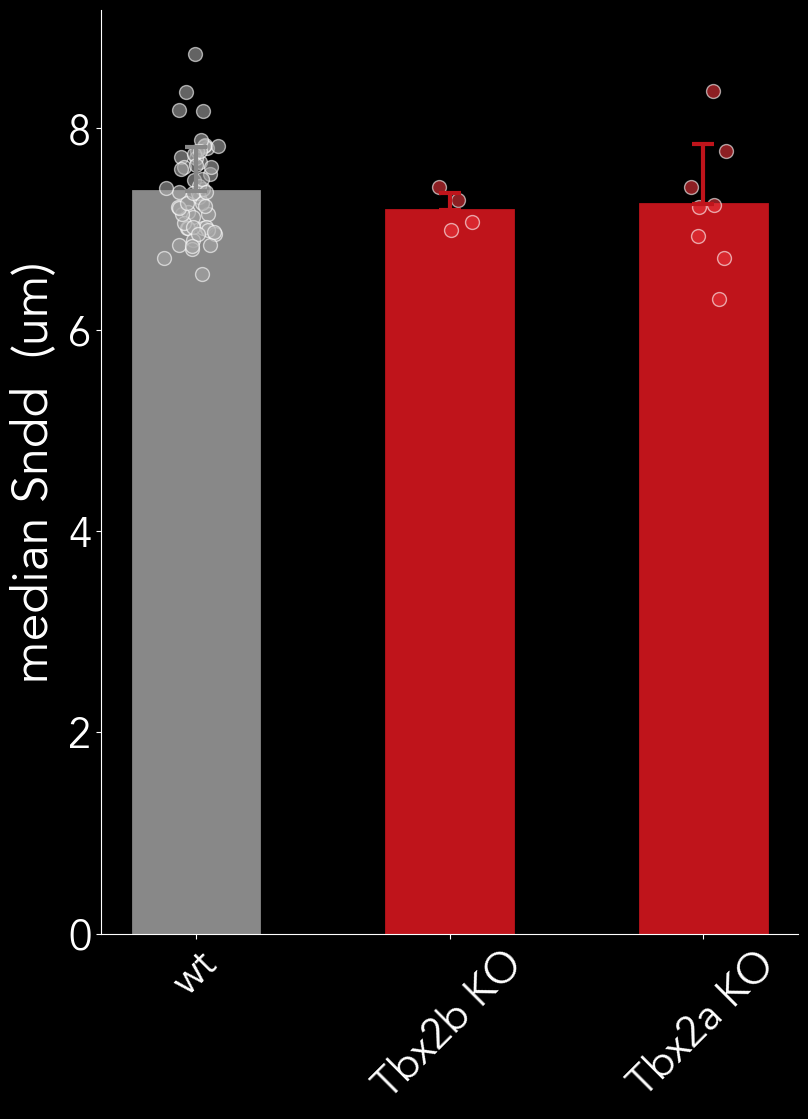

In [6]:

celltype = 'S'

#wildtype
dPath = "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/wt/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L01_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L01_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L03_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L04_002/', 
        '20250425_2ahetinx_5d_m2G_s2C_L04_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L07_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L08_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L09_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L10_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L11_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L12_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_002/',
        '20250425_2ahetinx_5d_m2G_s2C_L13_004/',
        '20250425_2ahetinx_5d_m2G_s2C_L14_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L06_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L09_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L10_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L11_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L12_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L13_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L01_002/',
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_002/",
        "20250123_5dpf_tbx2bhetinx_s2C_m2G_L01_004/",
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L02_004/',
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_002/', #issue with M nnd
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L04_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L05_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L06_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L07_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L08_004/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L09_004/' ,
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_002/',
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L10_004/',  #issue with M nnd
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_002/',
        '20250123_5dpf_tbx2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L01_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L02_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L04_002/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L06_002/', #toocurved
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L07_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L10_002/',
        #'220250807_5dpf_2bhetinx_s2C_m2G_L10_004', only m cones
        '220250807_5dpf_2bhetinx_s2C_m2G_L12_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L14_004/'
            ]

nndUMean_wt = np.empty((len(fPath),1))
nndUMean_wt[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_wt[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;

 #TBX2B KO FILES
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2bKO/"
fPath = [
# '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_002'#issue with M nnd 
        # '20250123_5dpf_tbx2bhetinx_s2C_m2G_L03_004/', #issue with M nnd
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_003/', #issue with M nnd
        # '220250807_5dpf_2bhetinx_s2C_m2G_L05_005/', #issue with M nnd
        # '220250807_5dpf_2bhetinx_s2C_m2G_L08_002/', #issue with M nnd
        '220250807_5dpf_2bhetinx_s2C_m2G_L08_004/',
        # '220250807_5dpf_2bhetinx_s2C_m2G_L11_002/', #missing folder - FIND IT AND RUN ANALYSIS ON IT
        '220250807_5dpf_2bhetinx_s2C_m2G_L11_004/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_002/',
        '220250807_5dpf_2bhetinx_s2C_m2G_L13_004/',
        ]

nndUMean_tbx2a = np.empty((len(fPath),1))
nndUMean_tbx2a[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2a[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;

#Tbx2a KO Samples     
dPath =  "Z:/Analysis/Householder/Misexpression_combined/MisexpressionGFPfiles/Tbx2aKO/"
fPath = [
        '20250425_2ahetinx_5d_m2G_s2C_L06_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L03_004/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_002/',
        '20250716_5d_m2G_s2C_2ahetinx_L05_004/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_002/',
        '20250716_5dp_tbx2ahetinx_s2C_m2G_L08_004/',
        '20250716_5dpf_tbx2ahetinx_s2C_m2G_L02_002/',
        ] 

nndUMean_tbx2b = np.empty((len(fPath),1))
nndUMean_tbx2b[:]=np.NaN
i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    nndUMean_tbx2b[i,0] = np.median(nnd) * 63.64/1024
    i=i+1;



plotname = ''
fH, axH = plt.subplots(figsize= [9,12])

i = 0
for nndM,geneColor,geneMarker in zip([nndUMean_wt,nndUMean_tbx2a,nndUMean_tbx2b],['#888888','#BF141B','#BF141B'],['o','o','o']):
    i = i+1
    jitter = np.random.randn(len(nndM))*0.05
    pH = plt.bar(i, np.mean(nndM), width=0.5, color=geneColor, linewidth = 2, edgecolor = geneColor);
    pH = plt.errorbar(i, np.mean(nndM), yerr = [[0],[np.std(nndM)]], ecolor=geneColor, elinewidth=3, capsize=8, capthick=3, zorder=9)
    pH = plt.scatter(np.ones(len(nndM))*i+jitter, nndM,
             color=lighten_color(geneColor,.75), zorder=8, marker = geneMarker, s=100, edgecolor=baseColor, linewidth=1, alpha = 0.6);

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xticks([1,2,3]);
axH.set_xticklabels(['wt','Tbx2b KO','Tbx2a KO']);
axH.xaxis.set_tick_params(rotation=45)
# axH.set_ylim([0,300]); # tbx2
axH.set_ylabel('median {0}ndd  (um)'.format(celltype), fontproperties=fontLabels)
plt.show()


#### Violin plots

TypeError: 'AxesSubplot' object is not subscriptable

Text(0, 0.5, 'Rndd  (um)')

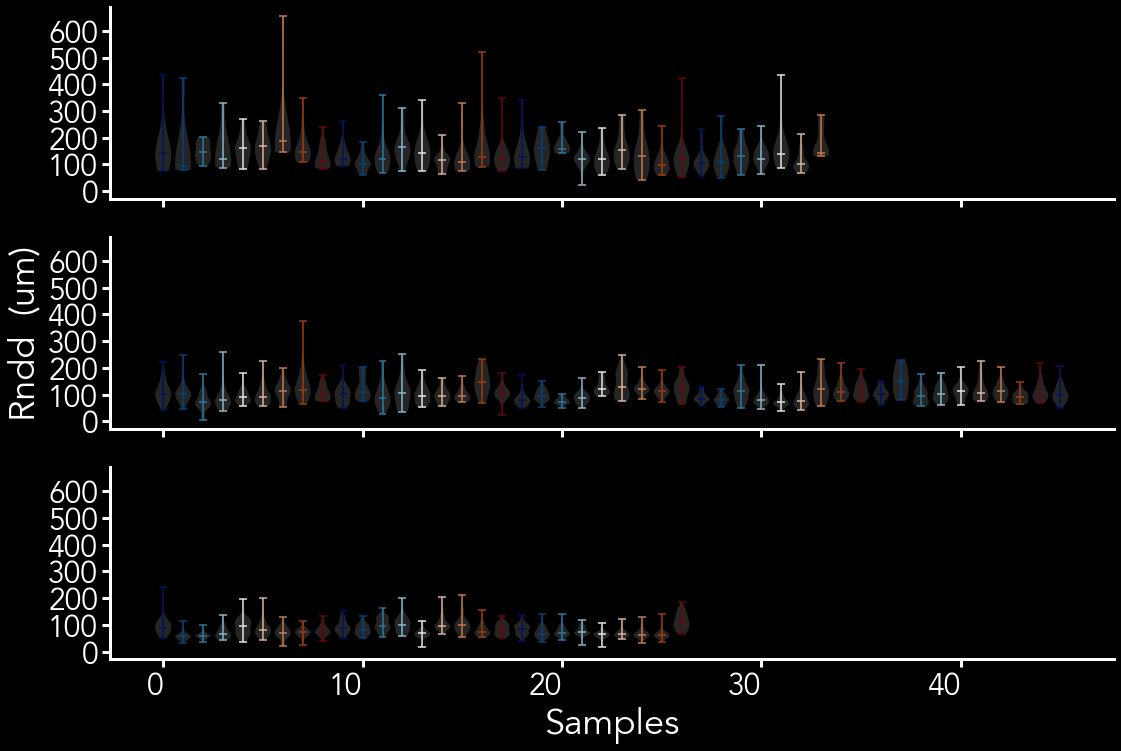

In [281]:
celltype = 'R'


plotname = ''
fH, axH = plt.subplots(3,1,figsize= [18,12], sharey=True, sharex = True)


dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/wt/'
fPath = [
'20200821_5dpf_xOG_s1mCh_uninj_i05b/',
# '20200821_5dpf_xOG_s1mCh_uninj_i05d/',
# '20200821_5dpf_xOG_s1mCh_uninj_i06b/',
# '20200821_5dpf_xOG_s1mCh_uninj_i06d/',
'20200821_5dpf_xOG_s1mCh_uninj_i101b/',
# '20200821_5dpf_xOG_s1mCh_uninj_i101d/',
'20200821_5dpf_xOG_s1mCh_uninj_i102b/',
'20200821_5dpf_xOG_s1mCh_uninj_i103b/',
'20200821_5dpf_xOG_s1mCh_uninj_i104b/',
'20200821_5dpf_xOG_s1mCh_uninj_i104d/',
'20201113_5dpf_xOG_s1mCh_uninj_i06b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i12b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i12d/',
'20201113_5dpf_xOG_s1mCh_uninjected_i13b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i15b/',
'20201113_5dpf_xOG_s1mCh_uninjected_i15d/',
'20210514_5dpf_xOG_s1C_uninj_L01b_withDAPI/',
'20210514_5dpf_xOG_s1C_uninj_L05b_withDAPI/',
'20210514_5dpf_xOG_s1C_uninj_L07b_withDAPI/',
'20221026_5dpf_xOG_s1C_wt_L01_002/',
'20221026_5dpf_xOG_s1C_wt_L01_004/',
'20221026_5dpf_xOG_s1C_wt_L02_002/',
'20221026_5dpf_xOG_s1C_wt_L03_002/',
'20221026_5dpf_xOG_s1C_wt_L03_004/',
'20221026_5dpf_xOG_s1C_wt_L04_002/',
'20221026_5dpf_xOG_s1C_wt_L04_004/',
'20221026_5dpf_xOG_s1C_wt_L05_002/',
'20221026_5dpf_xOG_s1C_wt_L05_004/',
'20221026_5dpf_xOG_s1C_wt_L06_002/',
# '20221026_5dpf_xOG_s1C_wt_L07_002/',
'20221026_5dpf_xOG_s1C_wt_L07_004/',
'20221026_5dpf_xOG_s1C_wt_L08_002/',
'20221026_5dpf_xOG_s1C_wt_L08_004/',
'20221026_5dpf_xOG_s1C_wt_L09_002/',
'20221026_5dpf_xOG_s1C_wt_L09_004/',
'20221026_5dpf_xOG_s1C_wt_L10_002/',
'20221026_5dpf_xOG_s1C_wt_L10_004/',
'20221026_5dpf_xOG_s1C_wt_L11_002/',
'20221026_5dpf_xOG_s1C_wt_L12_002/',
]


i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    vp = axH[0].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=True, showmedians=True)
    for body in vp['bodies']:
        body.set_facecolor(zfC[celltype])
    i=i+1;


dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/tbx2a/'
fPath = [
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i05b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i05d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i06b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i06d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i07b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i07d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i08b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i08d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i09b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i09d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i10b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i10d/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i11b/',
'20200821_5dpf_xOG_s1mCh_CRtbx2a_i11d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L01b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L02b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L03b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L04b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L05b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L06b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L07b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L07d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L08b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L08d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L09b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L10b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L11b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L11d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L12b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L13b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L13d/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L14b/',
'20210514_5dpf_xOG_s1C_CRtbx2a_L15b/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L01_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L01_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L02_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L02_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L03_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L05_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L05_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L06_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L06_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L07_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L07_004/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L08_002/',
'20221026_5dpf_xOG_s1C_tbx2aF0_L08_004/',
]


i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    vp = axH[1].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=True, showmedians=True)
    for body in vp['bodies']:
        body.set_facecolor(zfC[celltype])
    i=i+1;

    
dPath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Analysis/CRtbx2F0s/xOGs1C/tbx2b/'
fPath = [
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i09b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i10b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i10d/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i12b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i12d/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i13b/',
'20201113_5dpf_xOG_s1mCh_CRtbx2b_i13d/',
# '20201113_5dpf_xOG_s1mCh_CRtbx2b_i14b/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L01_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L01_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L02_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L02_004/',
# '20221026_5dpf_xOG_s1C_tbx2bF0_L03_002/',
# '20221026_5dpf_xOG_s1C_tbx2bF0_L03_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L04_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L04_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L05_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L06_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L06_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L07_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L07_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L08_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L08_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L09_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L09_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L10_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L10_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L11_002/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L11_004/',
'20221026_5dpf_xOG_s1C_tbx2bF0_L12_002/',
]    

i=0;
for filepath in fPath:
    nnd = np.load(dPath + filepath + celltype + '_nnd.npy')
    vp = axH[2].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=True, showmedians=True)
    for body in vp['bodies']:
        body.set_facecolor(zfC[celltype])
    i=i+1;


    
    
fontLabels = formatFigureMain(fH, axH[0], pH)
fontLabels = formatFigureMain(fH, axH[1], pH)
fontLabels = formatFigureMain(fH, axH[2], pH)
axH[2].set_xlabel('Samples', fontproperties=fontLabels)
axH[1].set_ylabel('{0}ndd  (um)'.format(celltype), fontproperties=fontLabels)

In [245]:

    
# vp[i] = axH[2].violinplot(dataset=nnd,positions=[i], widths=.8, showextrema=False, showmedians=True)

SyntaxError: invalid syntax (987083096.py, line 1)

IndexError: list index out of range

# NDD on other photoreceptors (from labels layers)

In [ ]:
dPath = '/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/CRnr2e3F0s/xOGaCT/wt/'
fPath = '20220121_5dpf_xOG_aCT_wt_L01_002/'
lPath = 'R_seg_curated.tiff'

labelData = imread(dPath + fPath + lPath)
# labelData

centroidData = calculateCentroidsFromLabels(labelData)
centroidData

In [ ]:
fH, axH = plt.subplots(figsize= [16,16])


pH = axH.imshow(labelData, cmap='bone')
pH = axH.scatter(centroidData[:,0],centroidData[:,1], color=zfC['R'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = 0.99);

## <a id='voronoi'>Voronoi</a>
Nice visualization, not extremely useful by itself


> [Back to index](#Index)

In [ ]:
np.size(vorU.regions[1])

In [ ]:
dPath = "/Users/angueyraaristjm/Documents/eelImaging/tempAnalysis/photoArrays/"
fUName = "U_missing.csv"
fNName = "N_points.csv"
nucsTiff = '20220121_5dpf_xOG_aCT_nr2e3_L06_004' + '.tiff'


Nucs = plt.imread(dPath + nucsName)

df =  pd.read_csv(dPath + fUName)
df = df.drop(columns = 'index')
U=df.to_numpy()
U = U[:,[1,0]]
vorU = scipy.spatial.Voronoi(U)

df =  pd.read_csv(dPath + fNName)
df = df.drop(columns = 'index')
N=df.to_numpy()
N = N[:,[1,0]]
vorN = scipy.spatial.Voronoi(N)

vorN = scipy.spatial.Voronoi(np.append(U,N,axis=0))

plotname = ''
fH, axH = plt.subplots(figsize= [16,16])

pH = axH.imshow(imread(dPath + nucsTiff), cmap='bone')


pH = plt.scatter(U[:,0],U[:,1], color=zfC['U'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .6);
pH = scipy.spatial.voronoi_plot_2d(vorU, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['U'], line_width=2, line_alpha=0.6, point_size=2)


regions, vertices = voronoi_finite_polygons_2d(vorU)
# colorize
for region in regions:
    polygon = vertices[region]
    plt.fill(*zip(*polygon), alpha=0.1)
    
# pH = plt.scatter(N[:,0],N[:,1], color=zfC['actb2'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .6);
# pH = voronoi_plot_2d(vorN, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['actb2'], line_width=2, line_alpha=0.6, point_size=2)

formatFigureMain(fH, axH, pH);

axH.set_xlim([-100,1124])
axH.set_ylim([-100,1124])

def p2umfx(x, pos): # formatter function
    s = '{:.2f}'.format(np.round(x * p2um,decimals=2))
    return s

axH.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))
axH.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(p2umfx))

# savePath = '/Users/angueyraaristjm/Library/CloudStorage/OneDrive-NationalInstitutesofHealth/zf/Manuscripts/2021_zfConeRNAseq/newGeneFigures/temp/'
# plt.savefig(savePath + goi + "_counts.svg", transparent=True, format="svg", bbox_inches = "tight")

### Lloyd's algorithm to make distribution more even
- Wikipedia: [Lloyd's algorithm](https://en.wikipedia.org/wiki/Lloyd%27s_algorithm)
- Implementation: [github.com/duhaime/lloyd](https://github.com/duhaime/lloyd)
    - Modified to use image boundaries (plus buffer) as mask for voronoi polygons during Lloyd's relaxation
    - Could use voronoi polygons to shapes or labels layers in napari [linkhere](https://napari.org/stable/gallery/shapes_to_labels.html)
        - there will be problems with vertices at infinity [someInforHere](https://stackoverflow.com/questions/23901943/voronoi-compute-exact-boundaries-of-every-region)
    

In [ ]:
# field = Field(np.multiply(np.ones(np.shape(U)),512)+np.random.normal(size=np.shape(U))) # start near the center and expand
field = Field(U, buffer = 20) #start from original locations of UV cones

nIterations = 2
with tqdm(total=nIterations, file=sys.stdout) as progBar:
# run Lloyd relaxation on the field of points
    for i in np.arange(0,nIterations):
        field.relax()
        progBar.update(1)



# get the resulting point positions
Ui = field.get_points()

vorUi = scipy.spatial.Voronoi(Ui)

# boundedRegions,boundedVertices = voronoi_finite_polygons_2d(vorUi)
# vorUi.regions = boundedRegions
# vorUi.vertices = boundedVertices


plotname = ''
fH, axH = plt.subplots(figsize= [16,16])


pH = plt.scatter(U[:,0],U[:,1], color=zfC['U'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .2);
pH = scipy.spatial.voronoi_plot_2d(vorU, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['U'], line_width=2, line_alpha=0.2, point_size=2)

pH = plt.scatter(Ui[:,0],Ui[:,1], color=zfC['S'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .8);
pH = scipy.spatial.voronoi_plot_2d(vorUi, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['S'], line_width=2, line_alpha=0.8, point_size=2)


border = [[0,0],[0,1024],[1024,1024],[1024,0]]
plt.fill(*zip(*border),alpha=0.5,facecolor='None',edgecolor='r')


regions, vertices = voronoi_finite_polygons_2d(vorUi)
clip = PolygonClipper()
# colorize
for region in regions:
    polygon = vertices[region]
    clipped = clip(polygon,border)
    plt.fill(*zip(*clipped), alpha=0.5)





# pH = plt.scatter(N[:,0],N[:,1], color=zfC['actb2'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .6);
# pH = voronoi_plot_2d(vorN, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['actb2'], line_width=2, line_alpha=0.6, point_size=2)

formatFigureMain(fH, axH, pH);


axH.set_xlim([-1000,2124])
axH.set_ylim([-1000,2124])
    
    

In [ ]:
kdtUi = scipy.spatial.KDTree(Ui)
kN = 1
Uinnd = np.empty((len(Ui),kN))
Uinnd[:]=np.NaN



for n in range(0,len(Ui)):
    temp = kdtUi.query(Ui[n],kN+1)
    for k in range (0,kN):
        Uinnd[n,k] = temp[0][k+1]


plotname = ''
fH, axH = plt.subplots(figsize= [12,6])
    
for k in range (0,kN):
    pH = plt.hist(Unnd[:,k], bins=40, color=zfC['U'], zorder=8 , edgecolor=baseColor, linewidth=0.5, alpha = .8);
    pH = plt.hist(Uinnd[:,k], bins=40, color=zfC['S'], zorder=8 , edgecolor=baseColor, linewidth=0.5, alpha = .8);

axH.set_xlim([0,np.max((Unnd)*1.2)])

formatFigureMain(fH, axH, pH);
plt.show();

print ('\n')
for k in range (0,kN):
    print ('Median for {0}-NDD : {1:.2f} pixels'.format(k+1,np.median(Unnd[:,k])))
    print ('Median for {0}-NDD after Lloyd\'s relaxation : {1:.2f} pixels'.format(k+1,np.median(Uinnd[:,k])))

In [ ]:
U = nnd.Centroids
vorU = nnd.vor

#### Clipping polygon example

In [ ]:
plotname = ''
fH, axH = plt.subplots(figsize= [16,16])

# pH = axH.imshow(Nucs, cmap='bone')

pH = plt.scatter(U[:,0],U[:,1], color=zfC['U'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .2);
pH = scipy.spatial.voronoi_plot_2d(vorU, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['U'], line_width=2, line_alpha=0.8, point_size=2)

# pH = plt.scatter(Ui[:,0],Ui[:,1], color=zfC['S'], zorder=8, marker = 'o', s=50, edgecolor=baseColor, linewidth=0.5, alpha = .8);
# pH = scipy.spatial.voronoi_plot_2d(vorUi, ax = axH, show_points = False, show_vertices=False, line_colors=zfC['S'], line_width=2, line_alpha=0.8, point_size=2)

# polygon = vorUi.vertices[vorUi.regions[24]]
# polygon = field.voronoi.vertices[field.voronoi.regions[30]+field.voronoi.regions[0]]
polygon = field.voronoi.vertices[field.voronoi.regions[12]]
plt.fill(*zip(*polygon),alpha=0.5,facecolor='r',edgecolor='k')


border = field.get_bb_pointsClockwise()
# border = [[0,0],[0,1024],[1024,1024],[1024,0]]
plt.fill(*zip(*border),alpha=0.5,facecolor='None',edgecolor='r')

clip = PolygonClipper()
clipped = clip(polygon,border)

plt.fill(*zip(*clipped),alpha=0.5,facecolor='g')

axH.set_xlim([-200,1200])
axH.set_ylim([-200,1200])